In [1]:
%%bash
pip install -q streamlit
pip install -q plotly

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

DATA_PATH = Path(
    "/content/CRA_combined.csv"
)

In [3]:
# Load the dataset first to define df_combined
df_combined = pd.read_csv(DATA_PATH)

# Check dataset dimensions
print("Dataset shape:", df_combined.shape)

# Check column names
print("\nColumn names:")
print(df_combined.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df_combined.info()

Dataset shape: (14685, 42)

Column names:
['account_id', 'customer_id', 'loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'origination_date', 'disbursal_channel', 'collateral_flag', 'target_default', 'age', 'gender', 'marital_status', 'education_level', 'employment_type', 'occupation_sector', 'years_employed', 'annual_income', 'region', 'city_tier', 'num_dependents', 'housing_type', 'years_at_residence', 'customer_since', 'total_bureau_records', 'total_bureau_outstanding', 'bureau_max_days_past_due', 'active_bureau_accounts', 'total_payments', 'late_payments', 'repayment_max_days_past_due', 'avg_days_past_due', 'total_emi_due', 'total_emi_paid', 'highest_outstanding_balance', 'total_collection_events', 'total_amount_recovered', 'payment_received_events', 'escalated_events', 'no_response_events', 'disputed_events']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14685 entries, 0 to 14684
Data columns (total 42 columns):
 #   Column

In [4]:
# Count missing values in each column
missing_summary = pd.DataFrame({
    "Missing_Count": df_combined.isnull().sum(),
    "Missing_Percentage": (
        df_combined.isnull().sum() / len(df_combined) * 100
    ).round(2)
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(by="Missing_Count", ascending=False)

print("Columns containing missing values:")
display(missing_summary)

Columns containing missing values:


,Missing_Count,Missing_Percentage
total_collection_events,10407,70.87
total_amount_recovered,10407,70.87
no_response_events,10407,70.87
disputed_events,10407,70.87
escalated_events,10407,70.87
payment_received_events,10407,70.87
bureau_max_days_past_due,1599,10.89
total_bureau_records,1462,9.96
total_bureau_outstanding,1462,9.96
active_bureau_accounts,1462,9.96


In [5]:
# Check whether bureau and collections fields are missing
# in the same loan accounts

bureau_missing = df_combined["total_bureau_records"].isnull()
collections_missing = df_combined["total_collection_events"].isnull()

missing_patterns = pd.DataFrame({
    "Pattern": [
        "Bureau and collections both missing",
        "Bureau missing, collections present",
        "Bureau present, collections missing",
        "Neither bureau nor collections missing"
    ],
    "Loan_Accounts": [
        (bureau_missing & collections_missing).sum(),
        (bureau_missing & ~collections_missing).sum(),
        (~bureau_missing & collections_missing).sum(),
        (~bureau_missing & ~collections_missing).sum()
    ]
})

missing_patterns["Percentage"] = (
    missing_patterns["Loan_Accounts"] / len(df_combined) * 100
).round(2)

display(missing_patterns)

,Pattern,Loan_Accounts,Percentage
0,Bureau and collections both missing,1017,6.93
1,"Bureau missing, collections present",445,3.03
2,"Bureau present, collections missing",9390,63.94
3,Neither bureau nor collections missing,3833,26.10


In [6]:
# Check whether the prediction target has any missing values
print("Missing target values:",
      df_combined["target_default"].isna().sum())

print("\nTarget distribution:")
display(
    df_combined["target_default"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Account_Count")
)

print("\nTarget distribution (%):")
display(
    (
        df_combined["target_default"]
        .value_counts(normalize=True, dropna=False)
        .sort_index() * 100
    ).round(2).to_frame("Percentage")
)

Missing target values: 0

Target distribution:


,Account_Count
target_default,
0,12321
1,2364



Target distribution (%):


,Percentage
target_default,
0,83.9
1,16.1


In [7]:
# Check whether repayment and collections timing information is available
date_related_columns = [
    col for col in df_combined.columns
    if "date" in col.lower() or "time" in col.lower()
]

print("Date/time-related columns:")
print(date_related_columns)

print("\nAvailable feature groups:")
feature_groups = {
    "Application and customer": [
        "loan_amount", "interest_rate_pct", "annual_income",
        "age", "years_employed"
    ],
    "Bureau": [
        "total_bureau_records", "total_bureau_outstanding",
        "bureau_max_days_past_due", "active_bureau_accounts"
    ],
    "Repayment": [
        "total_payments", "late_payments",
        "repayment_max_days_past_due", "avg_days_past_due",
        "total_emi_due", "total_emi_paid"
    ],
    "Collections": [
        "total_collection_events", "total_amount_recovered",
        "payment_received_events", "escalated_events",
        "no_response_events", "disputed_events"
    ]
}

for group, columns in feature_groups.items():
    available = [col for col in columns if col in df_combined.columns]
    print(f"{group}: {len(available)} features")

Date/time-related columns:
['origination_date']

Available feature groups:
Application and customer: 5 features
Bureau: 4 features
Repayment: 6 features
Collections: 6 features


In [8]:
from sklearn.model_selection import train_test_split

# Use features available from application, customer, and bureau data
selected_features = [
    "loan_type",
    "loan_purpose",
    "loan_amount",
    "interest_rate_pct",
    "tenure_months",
    "disbursal_channel",
    "collateral_flag",
    "age",
    "gender",
    "marital_status",
    "education_level",
    "employment_type",
    "occupation_sector",
    "years_employed",
    "annual_income",
    "region",
    "city_tier",
    "num_dependents",
    "housing_type",
    "years_at_residence",
    "total_bureau_records",
    "total_bureau_outstanding",
    "bureau_max_days_past_due",
    "active_bureau_accounts"
]

X_model = df_combined[selected_features].copy()
y_model = df_combined["target_default"].astype(int)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print("Training default rate:", round(y_train.mean() * 100, 2), "%")

print("\nTesting target distribution:")
print(y_test.value_counts())
print("Testing default rate:", round(y_test.mean() * 100, 2), "%")

Training feature shape: (11748, 24)
Testing feature shape: (2937, 24)

Training target distribution:
target_default
0    9857
1    1891
Name: count, dtype: int64
Training default rate: 16.1 %

Testing target distribution:
target_default
0    2464
1     473
Name: count, dtype: int64
Testing default rate: 16.1 %


In [9]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Preprocess numerical features
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build the complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the baseline model
logistic_model.fit(X_train, y_train)

# Generate predictions on unseen test data
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
auc = roc_auc_score(y_test, y_prob)
gini = (2 * auc) - 1

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
ks_statistic = np.max(tpr - fpr)

print("\n===== LOGISTIC REGRESSION BASELINE =====")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {auc:.4f}")
print(f"Gini:     {gini:.4f}")
print(f"KS:       {ks_statistic:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Numerical features: 13
Categorical features: 11

===== LOGISTIC REGRESSION BASELINE =====
Accuracy: 0.8379
ROC-AUC:  0.6569
Gini:     0.3138
KS:       0.2385

Confusion Matrix:
[[2455    9]
 [ 467    6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2464
           1       0.40      0.01      0.02       473

    accuracy                           0.84      2937
   macro avg       0.62      0.50      0.47      2937
weighted avg       0.77      0.84      0.77      2937



In [10]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Create a class-weighted version of the baseline model
weighted_logistic_model = clone(logistic_model)

weighted_logistic_model.set_params(
    classifier__class_weight="balanced"
)

# Train the model
weighted_logistic_model.fit(X_train, y_train)

# Predict on the same test set
y_pred_weighted = weighted_logistic_model.predict(X_test)
y_prob_weighted = weighted_logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
auc_weighted = roc_auc_score(y_test, y_prob_weighted)
gini_weighted = 2 * auc_weighted - 1

fpr_weighted, tpr_weighted, _ = roc_curve(
    y_test, y_prob_weighted
)
ks_weighted = np.max(tpr_weighted - fpr_weighted)

print("===== CLASS-WEIGHTED LOGISTIC REGRESSION =====")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_weighted):.4f}")
print(f"ROC-AUC:   {auc_weighted:.4f}")
print(f"Gini:      {gini_weighted:.4f}")
print(f"KS:        {ks_weighted:.4f}")
print(f"Precision: {precision_score(y_test, y_pred_weighted, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_weighted, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_weighted, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_weighted,
    zero_division=0
))

===== CLASS-WEIGHTED LOGISTIC REGRESSION =====
Accuracy:  0.6343
ROC-AUC:   0.6553
Gini:      0.3105
KS:        0.2420
Precision: 0.2376
Recall:    0.5751
F1-score:  0.3362

Confusion Matrix:
[[1591  873]
 [ 201  272]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.65      0.75      2464
           1       0.24      0.58      0.34       473

    accuracy                           0.63      2937
   macro avg       0.56      0.61      0.54      2937
weighted avg       0.78      0.63      0.68      2937



In [11]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1


In [12]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Calculate the class imbalance ratio using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", round(scale_pos_weight, 2))

# Create the XGBoost classifier
xgb_clf = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

# Wrap the classifier in a pipeline with our preprocessor
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_clf)
])

# Train the model
xgb_model.fit(X_train, y_train)

# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
auc_xgb = roc_auc_score(y_test, y_prob_xgb)
gini_xgb = 2 * auc_xgb - 1

fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(
    y_test, y_prob_xgb
)
ks_xgb = np.max(tpr_xgb - fpr_xgb)

print("\n===== XGBOOST RESULTS =====")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"ROC-AUC:   {auc_xgb:.4f}")
print(f"Gini:      {gini_xgb:.4f}")
print(f"KS:        {ks_xgb:.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_xgb, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_xgb, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    zero_division=0
))

Scale positive weight: 5.21

===== XGBOOST RESULTS =====
Accuracy:  0.6851
ROC-AUC:   0.6487
Gini:      0.2974
KS:        0.2223
Precision: 0.2478
Recall:    0.4693
F1-score:  0.3243

Confusion Matrix:
[[1790  674]
 [ 251  222]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.73      0.79      2464
           1       0.25      0.47      0.32       473

    accuracy                           0.69      2937
   macro avg       0.56      0.60      0.56      2937
weighted avg       0.78      0.69      0.72      2937



In [13]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate different thresholds using the existing test predictions
threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": round((tp + tn) / (tp + tn + fp + fn), 4),
        "Precision": round(precision_score(
            y_test, predictions, zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_test, predictions, zero_division=0
        ), 4),
        "F1_Score": round(f1_score(
            y_test, predictions, zero_division=0
        ), 4),
        "True_Positives": tp,
        "False_Positives": fp,
        "False_Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1_Score,True_Positives,False_Positives,False_Negatives
0,0.10,0.3824,0.1883,0.8562,0.3087,405,1746,68
1,0.15,0.6033,0.2322,0.6342,0.3399,300,992,173
2,0.20,0.7303,0.2731,0.4059,0.3265,192,511,281
3,0.25,0.7916,0.3317,0.2896,0.3093,137,276,336
4,0.30,0.8192,0.3694,0.1734,0.2360,82,140,391
5,0.35,0.8304,0.4074,0.1163,0.1809,55,80,418
6,0.40,0.8355,0.4306,0.0655,0.1138,31,41,442
7,0.45,0.8342,0.3158,0.0254,0.0470,12,26,461
8,0.50,0.8379,0.4000,0.0127,0.0246,6,9,467


In [14]:
from sklearn.model_selection import train_test_split

X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training set:", X_train_fit.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test.shape)

print("\nDefault rates:")
print("Training:", round(y_train_fit.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Model training set: (9398, 24)
Validation set: (2350, 24)
Final test set: (2937, 24)

Default rates:
Training: 16.1 %
Validation: 16.09 %
Test: 16.1 %


In [15]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import pandas as pd

# Clone the existing preprocessing and modelling pipeline
validation_logistic_model = clone(logistic_model)

# Account for class imbalance during training
validation_logistic_model.set_params(
    classifier__class_weight="balanced"
)

# Train using only the model training subset
validation_logistic_model.fit(X_train_fit, y_train_fit)

# Predict default probabilities on the validation set
y_val_prob = validation_logistic_model.predict_proba(X_val)[:, 1]

# Evaluate ranking performance
val_auc = roc_auc_score(y_val, y_val_prob)
val_gini = 2 * val_auc - 1

fpr_val, tpr_val, _ = roc_curve(y_val, y_val_prob)
val_ks = np.max(tpr_val - fpr_val)

print("===== VALIDATION RESULTS =====")
print(f"Validation ROC-AUC: {val_auc:.4f}")
print(f"Validation Gini:    {val_gini:.4f}")
print(f"Validation KS:      {val_ks:.4f}")

===== VALIDATION RESULTS =====
Validation ROC-AUC: 0.6793
Validation Gini:    0.3585
Validation KS:      0.2945


In [16]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results_val = []

for threshold in np.arange(0.10, 0.51, 0.025):
    predictions = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results_val.append({
        "Threshold": round(threshold, 3),
        "Accuracy": round(accuracy_score(y_val, predictions), 4),
        "Precision": round(precision_score(
            y_val, predictions, zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_val, predictions, zero_division=0
        ), 4),
        "F1_Score": round(f1_score(
            y_val, predictions, zero_division=0
        ), 4),
        "True_Positives": tp,
        "False_Positives": fp,
        "False_Negatives": fn
    })

threshold_results_val_df = pd.DataFrame(threshold_results_val)

# Display the strongest thresholds by F1-score
display(
    threshold_results_val_df
    .sort_values("F1_Score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

,Threshold,Accuracy,Precision,Recall,F1_Score,True_Positives,False_Positives,False_Negatives
0,0.500,0.6421,0.2550,0.6376,0.3643,241,704,137
1,0.475,0.6030,0.2447,0.7037,0.3631,266,821,112
2,0.450,0.5502,0.2273,0.7487,0.3487,283,962,95
3,0.425,0.5009,0.2142,0.7884,0.3369,298,1093,80
4,0.400,0.4494,0.2026,0.8254,0.3253,312,1228,66
5,0.375,0.4043,0.1951,0.8651,0.3184,327,1349,51
6,0.350,0.3591,0.1867,0.8889,0.3085,336,1464,42
7,0.325,0.3111,0.1800,0.9233,0.3013,349,1590,29
8,0.300,0.2753,0.1741,0.9365,0.2937,354,1679,24
9,0.275,0.2404,0.1689,0.9497,0.2869,359,1766,19


In [17]:
from sklearn.metrics import classification_report, confusion_matrix

selected_threshold = 0.475

y_val_pred = (y_val_prob >= selected_threshold).astype(int)

print(f"Selected threshold: {selected_threshold}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Performing (0)", "Default (1)"],
    zero_division=0
))

Selected threshold: 0.475

Confusion Matrix:
[[1151  821]
 [ 112  266]]

Classification Report:
                precision    recall  f1-score   support

Performing (0)       0.91      0.58      0.71      1972
   Default (1)       0.24      0.70      0.36       378

      accuracy                           0.60      2350
     macro avg       0.58      0.64      0.54      2350
  weighted avg       0.80      0.60      0.66      2350



In [18]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Predict default probabilities for the test set
y_test_prob = validation_logistic_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using the validation set
selected_threshold = 0.475
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

# Calculate ranking metrics
test_auc = roc_auc_score(y_test, y_test_prob)
test_gini = 2 * test_auc - 1

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
test_ks = np.max(tpr_test - fpr_test)

print("FINAL TEST SET RESULTS")
print(f"Threshold: {selected_threshold}")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")
print(f"Gini:      {test_gini:.4f}")
print(f"KS:        {test_ks:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Performing (0)", "Default (1)"],
    zero_division=0
))

FINAL TEST SET RESULTS
Threshold: 0.475
Accuracy:  0.5914
Precision: 0.2277
Recall:    0.6427
F1-score:  0.3363
ROC-AUC:   0.6570
Gini:      0.3141
KS:        0.2427

Confusion Matrix:
[[1433 1031]
 [ 169  304]]

Classification Report:
                precision    recall  f1-score   support

Performing (0)       0.89      0.58      0.70      2464
   Default (1)       0.23      0.64      0.34       473

      accuracy                           0.59      2937
     macro avg       0.56      0.61      0.52      2937
  weighted avg       0.79      0.59      0.65      2937



Business interpretation:
- The model correctly identifies 304 of 473 actual defaults.
- It misses 169 actual defaults.
- It flags 1,031 performing accounts as potential defaults.
- Of all accounts flagged as potential defaults, approximately 23% actually defaulted.

In [19]:
import pandas as pd
import numpy as np

# Retrieve the fitted preprocessing and Logistic Regression components
preprocessor = validation_logistic_model.named_steps["preprocessor"]
classifier = validation_logistic_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract model coefficients
coefficients = classifier.coef_[0]

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

# Sort by absolute coefficient magnitude
feature_importance = feature_importance.sort_values(
    "Absolute_Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 20 FEATURES BY ABSOLUTE COEFFICIENT")
display(feature_importance.head(20).round(4))

TOP 20 FEATURES BY ABSOLUTE COEFFICIENT


,Feature,Coefficient,Absolute_Importance
0,numeric__loan_amount,0.3589,0.3589
1,categorical__employment_type_Unemployed,0.3378,0.3378
2,numeric__annual_income,-0.2992,0.2992
3,numeric__bureau_max_days_past_due,0.2082,0.2082
4,numeric__years_employed,-0.2067,0.2067
5,numeric__interest_rate_pct,0.2060,0.2060
6,numeric__age,-0.1840,0.1840
7,categorical__loan_type_Mortgage,-0.1768,0.1768
8,categorical__loan_type_Auto Loan,0.1692,0.1692
9,categorical__loan_purpose_Travel,-0.1615,0.1615


In [20]:
# Separate features associated with higher and lower predicted default odds

positive_features = (
    feature_importance[feature_importance["Coefficient"] > 0]
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

negative_features = (
    feature_importance[feature_importance["Coefficient"] < 0]
    .sort_values("Coefficient", ascending=True)
    .head(10)
)

print("TOP 10 FEATURES ASSOCIATED WITH HIGHER DEFAULT ODDS")
display(positive_features[["Feature", "Coefficient"]].round(4))

print("TOP 10 FEATURES ASSOCIATED WITH LOWER DEFAULT ODDS")
display(negative_features[["Feature", "Coefficient"]].round(4))

TOP 10 FEATURES ASSOCIATED WITH HIGHER DEFAULT ODDS


,Feature,Coefficient
0,numeric__loan_amount,0.3589
1,categorical__employment_type_Unemployed,0.3378
3,numeric__bureau_max_days_past_due,0.2082
5,numeric__interest_rate_pct,0.2060
8,categorical__loan_type_Auto Loan,0.1692
12,categorical__loan_type_Personal Loan,0.1257
14,categorical__occupation_sector_Hospitality,0.1064
18,categorical__loan_purpose_Other,0.0961
20,categorical__loan_purpose_Wedding,0.0844
22,categorical__marital_status_Single,0.0811


TOP 10 FEATURES ASSOCIATED WITH LOWER DEFAULT ODDS


,Feature,Coefficient
2,numeric__annual_income,-0.2992
4,numeric__years_employed,-0.2067
6,numeric__age,-0.1840
7,categorical__loan_type_Mortgage,-0.1768
9,categorical__loan_purpose_Travel,-0.1615
10,numeric__active_bureau_accounts,-0.1556
11,categorical__employment_type_Self-Employed,-0.1355
13,categorical__occupation_sector_Construction,-0.1070
15,categorical__loan_type_Credit Card,-0.1053
16,categorical__marital_status_Widowed,-0.1004


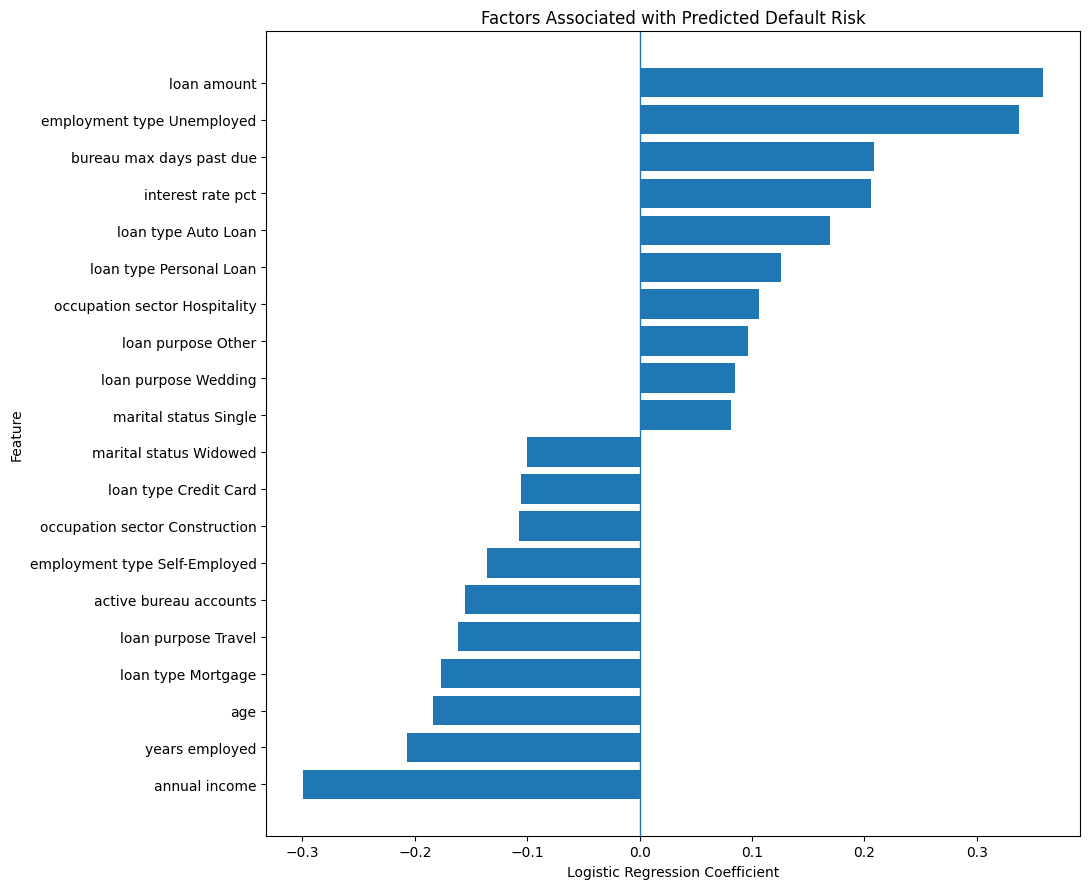

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the strongest positive and negative coefficients
top_positive = (
    feature_importance[feature_importance["Coefficient"] > 0]
    .nlargest(10, "Coefficient")
)

top_negative = (
    feature_importance[feature_importance["Coefficient"] < 0]
    .nsmallest(10, "Coefficient")
)

plot_data = pd.concat([top_positive, top_negative]).sort_values(
    "Coefficient"
)

# Make feature names easier to read
plot_data = plot_data.copy()
plot_data["Feature_Label"] = (
    plot_data["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

plt.figure(figsize=(11, 9))
plt.barh(plot_data["Feature_Label"], plot_data["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Factors Associated with Predicted Default Risk")
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
import numpy as np

# Create a validation results table
risk_analysis = pd.DataFrame({
    "Actual_Default": y_val.to_numpy(),
    "Predicted_Probability": y_val_prob
})

# Divide customers into five risk groups based on predicted probability
risk_analysis["Risk_Group"] = pd.qcut(
    risk_analysis["Predicted_Probability"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# Summarise default rates and predicted risk
risk_summary = (
    risk_analysis.groupby("Risk_Group", observed=True)
    .agg(
        Accounts=("Actual_Default", "size"),
        Actual_Defaults=("Actual_Default", "sum"),
        Actual_Default_Rate=("Actual_Default", "mean"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

risk_summary["Actual_Default_Rate"] = (
    risk_summary["Actual_Default_Rate"] * 100
).round(2)

risk_summary["Average_Predicted_Risk"] = (
    risk_summary["Average_Predicted_Risk"] * 100
).round(2)

display(risk_summary)

,Risk_Group,Accounts,Actual_Defaults,Actual_Default_Rate,Average_Predicted_Risk
0,Very Low,470,33,7.02,26.69
1,Low,470,44,9.36,38.00
2,Medium,470,62,13.19,46.11
3,High,470,91,19.36,54.81
4,Very High,470,148,31.49,68.82


Key findings
- Risk ranking works: The actual default rate increases consistently from 7.02% in the Very Low group to 31.49% in the Very High group.
- Clear risk separation: The Very High group has approximately 4.5 times the observed default rate of the Very Low group.
- Probability calibration is weak: For example, the Very High group has an average predicted risk of 68.82%, but its actual default rate is 31.49%.
- Business implication: The model could help prioritise accounts for further review, but its predicted probabilities should not yet be interpreted as reliable estimates of each customer's true default probability.

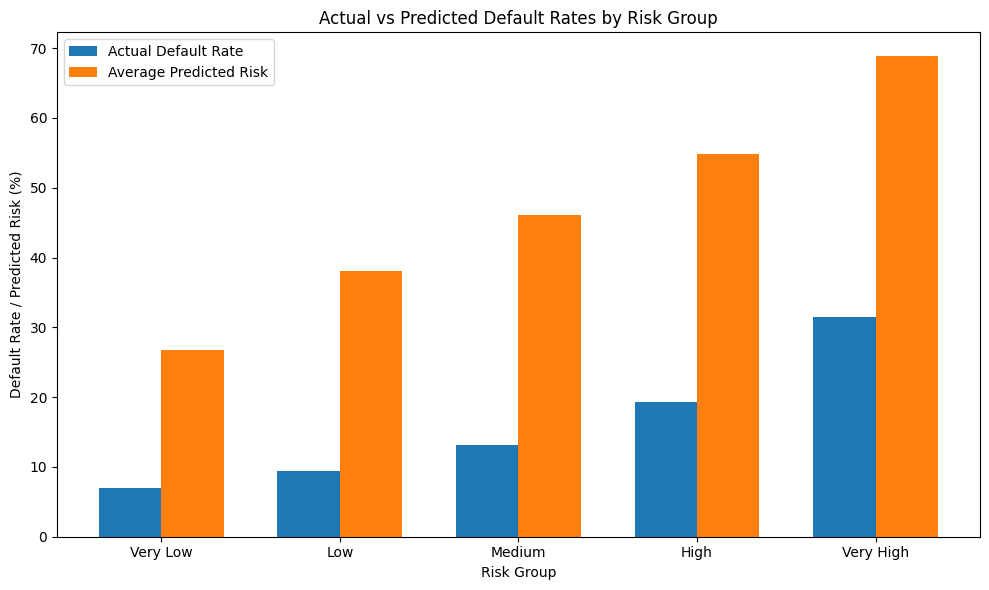

In [23]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(risk_summary))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    risk_summary["Actual_Default_Rate"],
    width,
    label="Actual Default Rate"
)

plt.bar(
    x + width / 2,
    risk_summary["Average_Predicted_Risk"],
    width,
    label="Average Predicted Risk"
)

plt.xticks(x, risk_summary["Risk_Group"], rotation=0)
plt.ylabel("Default Rate / Predicted Risk (%)")
plt.xlabel("Risk Group")
plt.title("Actual vs Predicted Default Rates by Risk Group")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Calibrate the existing model using validation data
calibrated_model = CalibratedClassifierCV(
    estimator=validation_logistic_model,
    method="sigmoid",
    cv="prefit"
)

calibrated_model.fit(X_val, y_val)

# Evaluate calibrated probabilities on the test set
y_test_prob_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

print("CALIBRATED MODEL — TEST SET")
print(f"ROC-AUC:       {roc_auc_score(y_test, y_test_prob_calibrated):.4f}")
print(f"Brier Score:   {brier_score_loss(y_test, y_test_prob_calibrated):.4f}")
print(f"Log Loss:      {log_loss(y_test, y_test_prob_calibrated):.4f}")

CALIBRATED MODEL — TEST SET
ROC-AUC:       0.6570
Brier Score:   0.1285
Log Loss:      0.4191


/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


In [25]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
import pandas as pd

# Original model probabilities
y_test_prob_original = validation_logistic_model.predict_proba(X_test)[:, 1]

# Compare both models on the same test set
comparison = pd.DataFrame({
    "Metric": ["ROC-AUC", "Brier Score", "Log Loss"],
    "Original Model": [
        roc_auc_score(y_test, y_test_prob_original),
        brier_score_loss(y_test, y_test_prob_original),
        log_loss(y_test, y_test_prob_original)
    ],
    "Calibrated Model": [
        roc_auc_score(y_test, y_test_prob_calibrated),
        brier_score_loss(y_test, y_test_prob_calibrated),
        log_loss(y_test, y_test_prob_calibrated)
    ]
})

display(comparison.round(4))

,Metric,Original Model,Calibrated Model
0,ROC-AUC,0.6570,0.6570
1,Brier Score,0.2262,0.1285
2,Log Loss,0.6444,0.4191


What this means:
- ROC-AUC: The model's ability to rank customers by default risk remains unchanged.
- Brier score: Decreased by approximately 43.2%, indicating better probability predictions.
- Log loss: Decreased by approximately 34.9%, also indicating improved probability predictions.

In [26]:
import pandas as pd

calibrated_risk_analysis = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Predicted_Probability": y_test_prob_calibrated
})

calibrated_risk_analysis["Risk_Group"] = pd.qcut(
    calibrated_risk_analysis["Predicted_Probability"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

calibrated_risk_summary = (
    calibrated_risk_analysis.groupby("Risk_Group", observed=True)
    .agg(
        Accounts=("Actual_Default", "size"),
        Actual_Defaults=("Actual_Default", "sum"),
        Actual_Default_Rate=("Actual_Default", "mean"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

calibrated_risk_summary["Actual_Default_Rate"] *= 100
calibrated_risk_summary["Average_Predicted_Risk"] *= 100

display(calibrated_risk_summary.round(2))

,Risk_Group,Accounts,Actual_Defaults,Actual_Default_Rate,Average_Predicted_Risk
0,Very Low,588,44,7.48,7.05
1,Low,587,75,12.78,10.92
2,Medium,587,69,11.75,14.13
3,High,587,109,18.57,18.02
4,Very High,588,176,29.93,28.94


Key findings
- Much better probability alignment: The predicted risk is close to the actual default rate in four of the five groups, with the largest difference in the Low group.
- Risk separation remains useful: The actual default rate increases from 7.48% in the Very Low group to 29.93% in the Very High group.
- The middle groups are not perfectly ordered: The Medium group has an actual default rate of 11.75%, slightly lower than the Low group's 12.78%. This is a reminder that risk ranking is not perfect.
- Practical implication: The calibrated probabilities may be more useful for portfolio-level risk estimation, but further validation is needed before using them for lending decisions.

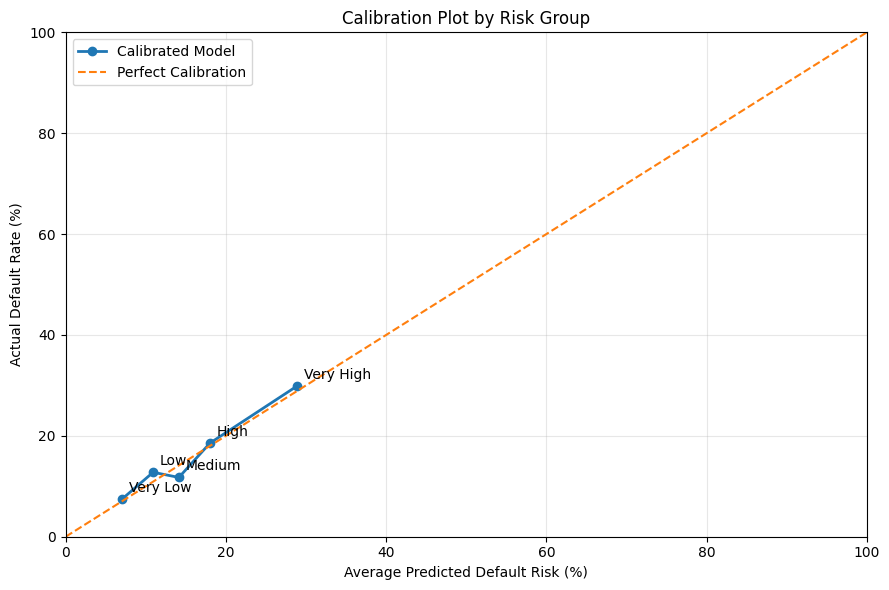

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    calibrated_risk_summary["Average_Predicted_Risk"],
    calibrated_risk_summary["Actual_Default_Rate"],
    marker="o",
    linewidth=2,
    label="Calibrated Model"
)

# Perfect calibration reference line
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    label="Perfect Calibration"
)

for _, row in calibrated_risk_summary.iterrows():
    plt.annotate(
        row["Risk_Group"],
        (
            row["Average_Predicted_Risk"],
            row["Actual_Default_Rate"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Average Predicted Default Risk (%)")
plt.ylabel("Actual Default Rate (%)")
plt.title("Calibration Plot by Risk Group")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, roc_curve
import pandas as pd
import numpy as np

# Calculate class imbalance from the same training subset
scale_pos_weight = (
    (y_train_fit == 0).sum() / (y_train_fit == 1).sum()
)

# Create the XGBoost classifier
xgb_val_clf = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

# Wrap the classifier in a pipeline with our preprocessor
xgb_validation_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_val_clf)
])

# Train using only the model training subset
xgb_validation_model.fit(X_train_fit, y_train_fit)

# Generate validation probabilities
y_val_prob_lr = validation_logistic_model.predict_proba(X_val)[:, 1]
y_val_prob_xgb = xgb_validation_model.predict_proba(X_val)[:, 1]

# Calculate comparison metrics
def calculate_ranking_metrics(y_true, probabilities):
    auc = roc_auc_score(y_true, probabilities)
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    ks = np.max(tpr - fpr)

    return {
        "ROC-AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks
    }

comparison_results = pd.DataFrame([
    {
        "Model": "Class-weighted Logistic Regression",
        **calculate_ranking_metrics(y_val, y_val_prob_lr)
    },
    {
        "Model": "XGBoost",
        **calculate_ranking_metrics(y_val, y_val_prob_xgb)
    }
])

display(comparison_results.round(4))

,Model,ROC-AUC,Gini,KS
0,Class-weighted Logistic Regression,0.6793,0.3585,0.2945
1,XGBoost,0.6385,0.2769,0.2329


What this means
- ROC-AUC: Logistic Regression distinguishes between defaulting and performing accounts better than XGBoost, although both models have room for improvement.
- Gini: Logistic Regression achieves a Gini coefficient of 0.3585, compared with 0.2769 for XGBoost.
- KS: Logistic Regression achieves a KS statistic of 0.2945, indicating better separation between the two classes at its best threshold.

In [29]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, roc_curve
import pandas as pd
import numpy as np

scale_pos_weight = (
    (y_train_fit == 0).sum() / (y_train_fit == 1).sum()
)

# Create the tuned XGBoost classifier
xgb_tuned_clf = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

# Wrap the tuned classifier in a pipeline with our preprocessor
xgb_tuned_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_tuned_clf)
])

xgb_tuned_model.fit(X_train_fit, y_train_fit)

y_val_prob_xgb_tuned = xgb_tuned_model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_val_prob_xgb_tuned)
fpr, tpr, _ = roc_curve(y_val, y_val_prob_xgb_tuned)

tuned_results = pd.DataFrame([
    {
        "Model": "Class-weighted Logistic Regression",
        "ROC-AUC": roc_auc_score(y_val, y_val_prob_lr),
        "Gini": 2 * roc_auc_score(y_val, y_val_prob_lr) - 1,
        "KS": np.max(
            roc_curve(y_val, y_val_prob_lr)[1]
            - roc_curve(y_val, y_val_prob_lr)[0]
        )
    },
    {
        "Model": "Original XGBoost",
        "ROC-AUC": roc_auc_score(y_val, y_val_prob_xgb),
        "Gini": 2 * roc_auc_score(y_val, y_val_prob_xgb) - 1,
        "KS": np.max(
            roc_curve(y_val, y_val_prob_xgb)[1]
            - roc_curve(y_val, y_val_prob_xgb)[0]
        )
    },
    {
        "Model": "Tuned XGBoost",
        "ROC-AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": np.max(tpr - fpr)
    }
])

display(tuned_results.round(4))

,Model,ROC-AUC,Gini,KS
0,Class-weighted Logistic Regression,0.6793,0.3585,0.2945
1,Original XGBoost,0.6385,0.2769,0.2329
2,Tuned XGBoost,0.6571,0.3143,0.2613


TOP 15 XGBOOST FEATURES


,Feature,Importance
0,employment type Unemployed,0.0570
1,annual income,0.0342
2,loan type Mortgage,0.0222
3,bureau max days past due,0.0207
4,age,0.0197
5,loan amount,0.0194
6,years employed,0.0188
7,occupation sector Government,0.0175
8,occupation sector Manufacturing,0.0169
9,marital status Widowed,0.0166


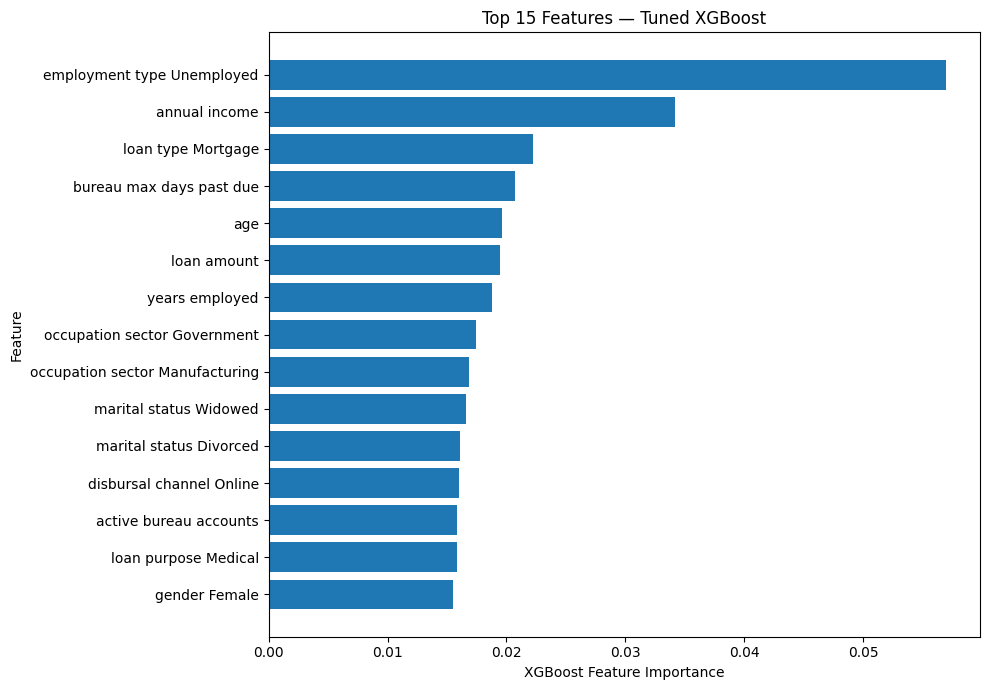

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Access the preprocessor and the classifier from the Pipeline
preprocessor = xgb_tuned_model.named_steps["preprocessor"]
xgb_clf = xgb_tuned_model.named_steps["classifier"]

# 2. Extract the correct feature names generated after preprocessing (e.g. one-hot encoding)
processed_feature_names = preprocessor.get_feature_names_out()

# Extract feature importance from the tuned XGBoost classifier
xgb_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": xgb_clf.feature_importances_
})

# Make feature names easier to read by stripping the step prefixes
xgb_importance["Feature"] = (
    xgb_importance["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

xgb_importance = xgb_importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("TOP 15 XGBOOST FEATURES")
display(xgb_importance.head(15).round(4))

# Visualise the top 15 features
top_features = xgb_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features — Tuned XGBoost")
plt.tight_layout()
plt.show()

In [31]:
# Inspect all columns related to repayment, collections, and bureau data
related_columns = [
    col for col in df_combined.columns
    if any(keyword in col.lower()
           for keyword in ["repay", "payment", "late", "overdue",
                           "collection", "bureau", "past_due", "dpd"])
]

print("Relevant columns in df_combined:")
for col in related_columns:
    print(f"- {col}")

print("\nDataset shape:", df_combined.shape)

Relevant columns in df_combined:
- collateral_flag
- total_bureau_records
- total_bureau_outstanding
- bureau_max_days_past_due
- active_bureau_accounts
- total_payments
- late_payments
- repayment_max_days_past_due
- avg_days_past_due
- total_collection_events
- payment_received_events
- escalated_events

Dataset shape: (14685, 42)


In [32]:
import pandas as pd
import numpy as np

repayment_collection_features = [
    "total_payments",
    "late_payments",
    "repayment_max_days_past_due",
    "avg_days_past_due",
    "total_collection_events",
    "payment_received_events",
    "escalated_events"
]

# Summary statistics
print("FEATURE SUMMARY")
display(
    df_combined[repayment_collection_features]
    .describe()
    .T
    .round(2)
)

# Missing values
print("MISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing_Count": df_combined[repayment_collection_features].isna().sum(),
    "Missing_Percentage": (
        df_combined[repayment_collection_features].isna().mean() * 100
    ).round(2)
})

display(missing_summary)

# Compare feature averages by default status
print("FEATURE AVERAGES BY DEFAULT STATUS")
default_comparison = (
    df_combined.groupby("target_default")[repayment_collection_features]
    .mean()
    .T
    .rename(columns={
        0: "Performing_Accounts",
        1: "Defaulted_Accounts"
    })
)

display(default_comparison.round(2))

FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
total_payments,14685.0,12.00,0.00,12.0,12.00,12.00,12.00,12.00
late_payments,14685.0,1.41,1.18,0.0,1.00,1.00,2.00,7.00
repayment_max_days_past_due,14685.0,33.72,27.77,0.0,11.00,25.00,58.00,89.00
avg_days_past_due,14685.0,4.47,4.39,0.0,1.08,3.17,6.83,34.75
total_collection_events,4278.0,2.02,0.81,1.0,1.00,2.00,3.00,3.00
payment_received_events,4278.0,0.40,0.58,0.0,0.00,0.00,1.00,3.00
escalated_events,4278.0,0.39,0.58,0.0,0.00,0.00,1.00,3.00


MISSING VALUES


,Missing_Count,Missing_Percentage
total_payments,0,0.00
late_payments,0,0.00
repayment_max_days_past_due,0,0.00
avg_days_past_due,0,0.00
total_collection_events,10407,70.87
payment_received_events,10407,70.87
escalated_events,10407,70.87


FEATURE AVERAGES BY DEFAULT STATUS


target_default,Performing_Accounts,Defaulted_Accounts
total_payments,12.00,12.00
late_payments,1.34,1.76
repayment_max_days_past_due,32.29,41.15
avg_days_past_due,4.17,6.04
total_collection_events,2.02,2.02
payment_received_events,0.39,0.41
escalated_events,0.39,0.38


In [33]:
# Inspect date-related columns
date_columns = [
    col for col in df_combined.columns
    if "date" in col.lower() or "time" in col.lower()
]

print("DATE/TIME COLUMNS:")
for col in date_columns:
    print(f"\n{col}")
    print(df_combined[col].head(5).to_list())

# Inspect repayment and collection information alongside the target
inspection_columns = [
    "account_id",
    "origination_date",
    "target_default",
    "late_payments",
    "repayment_max_days_past_due",
    "avg_days_past_due",
    "total_collection_events",
    "payment_received_events",
    "escalated_events"
]

display(df_combined[inspection_columns].head(10))

DATE/TIME COLUMNS:

origination_date
['Oct 18, 2022, 05:30:00 AM', 'Dec 19, 2022, 05:30:00 AM', 'Nov 8, 2023, 05:30:00 AM', 'Apr 6, 2020, 05:30:00 AM', 'Apr 15, 2023, 05:30:00 AM']


,account_id,origination_date,target_default,late_payments,repayment_max_days_past_due,avg_days_past_due,total_collection_events,payment_received_events,escalated_events
0,ACC200001,"Oct 18, 2022, 05:30:00 AM",1,4,14,2.500000,NaN,NaN,NaN
1,ACC200002,"Dec 19, 2022, 05:30:00 AM",0,2,45,7.000000,3.0,1.0,1.0
2,ACC200003,"Nov 8, 2023, 05:30:00 AM",0,1,24,2.000000,NaN,NaN,NaN
3,ACC200004,"Apr 6, 2020, 05:30:00 AM",0,1,8,0.666667,NaN,NaN,NaN
4,ACC200005,"Apr 15, 2023, 05:30:00 AM",0,1,21,1.750000,NaN,NaN,NaN
5,ACC200006,"Mar 20, 2022, 05:30:00 AM",0,3,64,10.083333,1.0,0.0,0.0
6,ACC200007,"Jul 9, 2021, 05:30:00 AM",0,3,27,4.750000,NaN,NaN,NaN
7,ACC200008,"Nov 6, 2023, 05:30:00 AM",0,0,0,0.000000,NaN,NaN,NaN
8,ACC200009,"Nov 18, 2018, 05:30:00 AM",0,2,50,10.500000,2.0,0.0,1.0
9,ACC200010,"Mar 26, 2019, 05:30:00 AM",0,2,78,13.083333,NaN,NaN,NaN


In [34]:
import pandas as pd
import numpy as np

# Features available in the repayment summary
repayment_features = [
    "total_emi_due",
    "total_emi_paid",
    "highest_outstanding_balance",
    "late_payments",
    "repayment_max_days_past_due",
    "avg_days_past_due"
]

# Compare repayment behaviour by default status
repayment_comparison = (
    df_combined.groupby("target_default")[repayment_features]
    .mean()
    .T
    .rename(columns={
        0: "Performing_Accounts",
        1: "Defaulted_Accounts"
    })
)

# Calculate relative differences between the two groups
repayment_comparison["Difference"] = (
    repayment_comparison["Defaulted_Accounts"]
    - repayment_comparison["Performing_Accounts"]
)

display(repayment_comparison.round(2))

# Calculate repayment shortfall
df_combined["emi_shortfall"] = (
    df_combined["total_emi_due"]
    - df_combined["total_emi_paid"]
)

print("\nEMI SHORTFALL BY DEFAULT STATUS")

shortfall_summary = (
    df_combined.groupby("target_default")["emi_shortfall"]
    .agg(["mean", "median", "min", "max"])
    .rename(index={
        0: "Performing_Accounts",
        1: "Defaulted_Accounts"
    })
)

display(shortfall_summary.round(2))

target_default,Performing_Accounts,Defaulted_Accounts,Difference
total_emi_due,10392.35,11490.89,1098.54
total_emi_paid,9915.06,10704.65,789.59
highest_outstanding_balance,37989.46,53155.05,15165.60
late_payments,1.34,1.76,0.42
repayment_max_days_past_due,32.29,41.15,8.86
avg_days_past_due,4.17,6.04,1.87



EMI SHORTFALL BY DEFAULT STATUS


,mean,median,min,max
target_default,,,,
Performing_Accounts,477.28,0.00,0.0,19254.40
Defaulted_Accounts,786.23,199.34,0.0,12641.85


In [35]:
# Check whether repayment behaviour differs between performing and defaulted accounts

repayment_check = df_combined.groupby("target_default")[
    [
        "late_payments",
        "repayment_max_days_past_due",
        "avg_days_past_due",
        "total_emi_due",
        "total_emi_paid",
        "highest_outstanding_balance"
    ]
].mean().round(2)

print("Average repayment features by target:")
display(repayment_check)

print("\nTarget definition:")
print(df_combined["target_default"].value_counts())

Average repayment features by target:


,late_payments,repayment_max_days_past_due,avg_days_past_due,total_emi_due,total_emi_paid,highest_outstanding_balance
target_default,,,,,,
0,1.34,32.29,4.17,10392.35,9915.06,37989.46
1,1.76,41.15,6.04,11490.89,10704.65,53155.05



Target definition:
target_default
0    12321
1     2364
Name: count, dtype: int64


In [36]:
# Check whether monthly repayment records are available
print("Columns in the combined dataset:")
print(df_combined.columns.tolist())

print("\nRepayment-related columns:")
print([
    col for col in df_combined.columns
    if any(word in col.lower() for word in
           ["repayment", "payment_month", "late_payments",
            "days_past_due", "emi_due", "emi_paid"])
])

Columns in the combined dataset:
['account_id', 'customer_id', 'loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'origination_date', 'disbursal_channel', 'collateral_flag', 'target_default', 'age', 'gender', 'marital_status', 'education_level', 'employment_type', 'occupation_sector', 'years_employed', 'annual_income', 'region', 'city_tier', 'num_dependents', 'housing_type', 'years_at_residence', 'customer_since', 'total_bureau_records', 'total_bureau_outstanding', 'bureau_max_days_past_due', 'active_bureau_accounts', 'total_payments', 'late_payments', 'repayment_max_days_past_due', 'avg_days_past_due', 'total_emi_due', 'total_emi_paid', 'highest_outstanding_balance', 'total_collection_events', 'total_amount_recovered', 'payment_received_events', 'escalated_events', 'no_response_events', 'disputed_events', 'emi_shortfall']

Repayment-related columns:
['bureau_max_days_past_due', 'late_payments', 'repayment_max_days_past_due', 'avg_days_past_due', 'total_e

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

# Construct the extended datasets using baseline features + repayment features
extended_features = selected_features + repayment_features

# Create train and validation splits for the extended feature set
X_extended_train_fit = df_combined.loc[X_train_fit.index, extended_features].copy()
X_extended_val = df_combined.loc[X_val.index, extended_features].copy()
y_extended_train_fit = y_train_fit.copy()
y_extended_val = y_val.copy()

# Identify numeric and categorical columns in the extended dataset
numeric_features_extended = X_extended_train_fit.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_extended = X_extended_train_fit.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numeric preprocessing
numeric_transformer_extended = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_extended = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Build a fresh preprocessor for all 31 input features
preprocessor_extended = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer_extended, numeric_features_extended),
    ("categorical", categorical_transformer_extended, categorical_features_extended)
])

# Build the extended model
extended_logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor_extended),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train using the extended training split
extended_logistic_model.fit(
    X_extended_train_fit,
    y_extended_train_fit
)

# Generate validation probabilities
y_extended_val_prob = extended_logistic_model.predict_proba(
    X_extended_val
)[:, 1]

# Check whether repayment features are now included
transformed_names = (
    extended_logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Numeric input features:", len(numeric_features_extended))
print("Categorical input features:", len(categorical_features_extended))
print("Total transformed features:", len(transformed_names))

print("\nRepayment features included in preprocessing:")
for feature in repayment_features:
    print(
        feature,
        "->",
        any(feature in name for name in transformed_names)
    )

# Compare validation performance
baseline_auc = roc_auc_score(y_val, y_val_prob)
extended_auc = roc_auc_score(y_extended_val, y_extended_val_prob)

print("\nBaseline validation ROC-AUC:", round(baseline_auc, 4))
print("Extended validation ROC-AUC:", round(extended_auc, 4))
print("ROC-AUC difference:", round(extended_auc - baseline_auc, 4))

Numeric input features: 19
Categorical input features: 11
Total transformed features: 79

Repayment features included in preprocessing:
total_emi_due -> True
total_emi_paid -> True
highest_outstanding_balance -> True
late_payments -> True
repayment_max_days_past_due -> True
avg_days_past_due -> True

Baseline validation ROC-AUC: 0.6793
Extended validation ROC-AUC: 0.6889
ROC-AUC difference: 0.0096


In [38]:
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score
import pandas as pd

# Baseline metrics
baseline_auc = roc_auc_score(y_val, y_val_prob)
baseline_gini = 2 * baseline_auc - 1
baseline_ks = ks_2samp(
    y_val_prob[y_val == 0],
    y_val_prob[y_val == 1]
).statistic

# Extended model metrics
extended_auc = roc_auc_score(y_extended_val, y_extended_val_prob)
extended_gini = 2 * extended_auc - 1
extended_ks = ks_2samp(
    y_extended_val_prob[y_extended_val == 0],
    y_extended_val_prob[y_extended_val == 1]
).statistic

# Comparison table
model_comparison = pd.DataFrame({
    "Metric": ["ROC-AUC", "Gini", "KS"],
    "Baseline (24 features)": [
        baseline_auc, baseline_gini, baseline_ks
    ],
    "Extended (31 features)": [
        extended_auc, extended_gini, extended_ks
    ]
})

model_comparison["Difference"] = (
    model_comparison["Extended (31 features)"]
    - model_comparison["Baseline (24 features)"]
)

display(model_comparison.round(4))

,Metric,Baseline (24 features),Extended (31 features),Difference
0,ROC-AUC,0.6793,0.6889,0.0096
1,Gini,0.3585,0.3777,0.0192
2,KS,0.2945,0.2933,-0.0012


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Apply the same provisional threshold
threshold = 0.475

y_extended_val_pred = (
    y_extended_val_prob >= threshold
).astype(int)

print("EXTENDED LOGISTIC REGRESSION — VALIDATION RESULTS")
print(f"Threshold: {threshold}")
print(f"Accuracy:  {accuracy_score(y_extended_val, y_extended_val_pred):.4f}")
print(f"Precision: {precision_score(y_extended_val, y_extended_val_pred):.4f}")
print(f"Recall:    {recall_score(y_extended_val, y_extended_val_pred):.4f}")
print(f"F1-score:  {f1_score(y_extended_val, y_extended_val_pred):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_extended_val, y_extended_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_extended_val,
    y_extended_val_pred,
    target_names=["Performing", "Default"]
))

EXTENDED LOGISTIC REGRESSION — VALIDATION RESULTS
Threshold: 0.475
Accuracy:  0.6187
Precision: 0.2490
Recall:    0.6799
F1-score:  0.3645

Confusion Matrix:
[[1197  775]
 [ 121  257]]

Classification Report:
              precision    recall  f1-score   support

  Performing       0.91      0.61      0.73      1972
     Default       0.25      0.68      0.36       378

    accuracy                           0.62      2350
   macro avg       0.58      0.64      0.55      2350
weighted avg       0.80      0.62      0.67      2350



### Confusion matrix interpretation
- 257 defaults correctly identified: The model catches approximately 68% of actual defaults.

- 121 defaults missed: These accounts were predicted as performing.

- 775 false alarms: These performing accounts were incorrectly flagged as potential defaults.

- Precision of 24.9%: Roughly one in four accounts flagged as default actually defaulted in this validation sample.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

threshold = 0.475

# Baseline predictions
baseline_pred = (y_val_prob >= threshold).astype(int)

# Extended model predictions
extended_pred = (y_extended_val_prob >= threshold).astype(int)

# Summarise both models
results = []

for model_name, actual, predicted in [
    ("Baseline Logistic Regression", y_val, baseline_pred),
    ("Extended Logistic Regression", y_extended_val, extended_pred)
]:
    tn, fp, fn, tp = confusion_matrix(actual, predicted).ravel()

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1-score": f1_score(actual, predicted),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,True Negatives
0,Baseline Logistic Regression,0.6030,0.2447,0.7037,0.3631,266,821,112,1151
1,Extended Logistic Regression,0.6187,0.2490,0.6799,0.3645,257,775,121,1197


In [41]:
# Extract feature names and fitted coefficients
feature_names = (
    extended_logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    extended_logistic_model
    .named_steps["classifier"]
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

top_features = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
).head(20)

display(top_features.round(4))

,Feature,Coefficient,Absolute_Coefficient
56,categorical__employment_type_Unemployed,0.2885,0.2885
6,numeric__annual_income,-0.2599,0.2599
18,numeric__avg_days_past_due,0.2048,0.2048
1,numeric__interest_rate_pct,0.1993,0.1993
26,categorical__loan_type_Mortgage,-0.1860,0.1860
11,numeric__bureau_max_days_past_due,0.1789,0.1789
23,categorical__loan_type_Auto Loan,0.1759,0.1759
15,numeric__highest_outstanding_balance,0.1681,0.1681
5,numeric__years_employed,-0.1655,0.1655
0,numeric__loan_amount,0.1585,0.1585


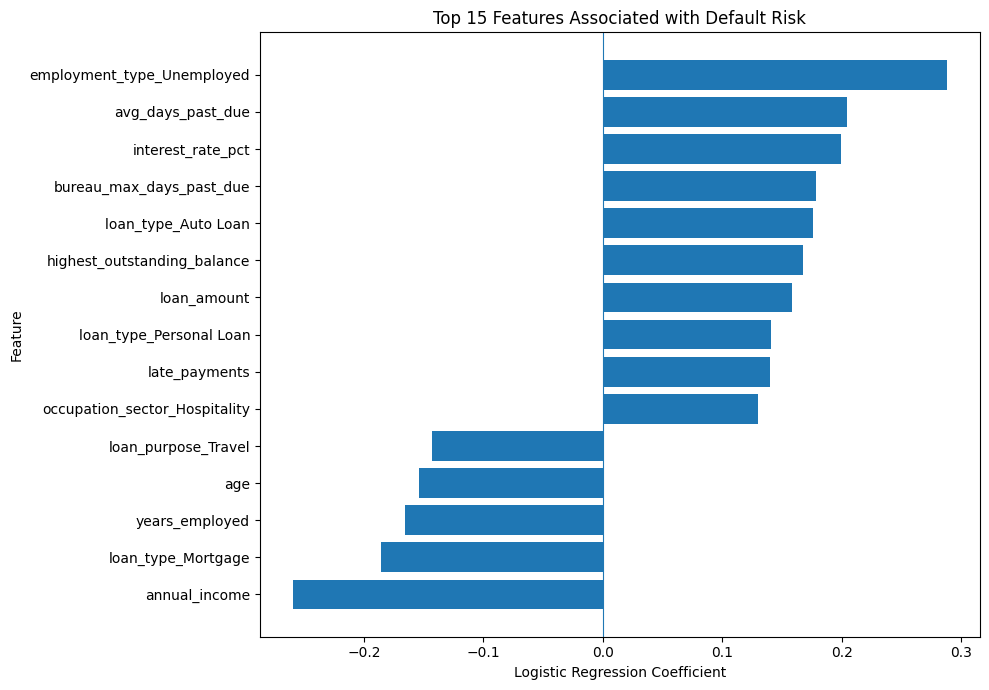

In [42]:
import matplotlib.pyplot as plt

# Select the 15 strongest features by absolute coefficient
top_15 = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
).head(15).sort_values("Coefficient")

# Create the chart
plt.figure(figsize=(10, 7))

plt.barh(
    top_15["Feature"].str.replace(
        "numeric__", "", regex=False
    ).str.replace(
        "categorical__", "", regex=False
    ),
    top_15["Coefficient"]
)

plt.axvline(0, linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features Associated with Default Risk")
plt.tight_layout()
plt.show()

Key findings from the chart
- Unemployment has the strongest positive coefficient (+0.2885), indicating higher predicted default odds relative to the reference employment category.
- Average days past due (+0.2048) and late payments (+0.1403) highlight the importance of repayment behaviour.
- Annual income has the strongest negative coefficient (−0.2599), suggesting higher income is associated with lower predicted default odds.
- Years employed (−0.1655) is also negatively associated with default risk.
- Bureau delinquency (+0.1789) and outstanding balance (+0.1681) provide additional credit-risk signals.
These are model associations, not causal relationships. Also, the numeric features were standardised, so coefficient magnitudes should be interpreted on the transformed scale.

In [43]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from scipy.stats import ks_2samp

# Prepare the extended test set directly from df_combined using the test split index
X_extended_test = df_combined.loc[X_test.index, extended_features].copy()
y_extended_test = y_test.copy()

# Predict default probabilities
y_extended_test_prob = extended_logistic_model.predict_proba(
    X_extended_test
)[:, 1]

# Apply the selected threshold
threshold = 0.475
y_extended_test_pred = (
    y_extended_test_prob >= threshold
).astype(int)

# Calculate performance metrics
auc = roc_auc_score(y_extended_test, y_extended_test_prob)
gini = 2 * auc - 1
ks = ks_2samp(
    y_extended_test_prob[y_extended_test == 0],
    y_extended_test_prob[y_extended_test == 1]
).statistic

print("EXTENDED LOGISTIC REGRESSION — TEST RESULTS")
print(f"Threshold: {threshold}")
print(f"Accuracy:  {accuracy_score(y_extended_test, y_extended_test_pred):.4f}")
print(f"Precision: {precision_score(y_extended_test, y_extended_test_pred):.4f}")
print(f"Recall:    {recall_score(y_extended_test, y_extended_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_extended_test, y_extended_test_pred):.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Gini:      {gini:.4f}")
print(f"KS:        {ks:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_extended_test, y_extended_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_extended_test,
    y_extended_test_pred,
    target_names=["Performing", "Default"]
))

EXTENDED LOGISTIC REGRESSION — TEST RESULTS
Threshold: 0.475
Accuracy:  0.6149
Precision: 0.2338
Recall:    0.6110
F1-score:  0.3382
ROC-AUC:   0.6672
Gini:      0.3344
KS:        0.2498

Confusion Matrix:
[[1517  947]
 [ 184  289]]

Classification Report:
              precision    recall  f1-score   support

  Performing       0.89      0.62      0.73      2464
     Default       0.23      0.61      0.34       473

    accuracy                           0.61      2937
   macro avg       0.56      0.61      0.53      2937
weighted avg       0.79      0.61      0.67      2937



In [44]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss
import numpy as np

# Calibrate using the validation set, not the test set
calibrated_extended_model = CalibratedClassifierCV(
    estimator=extended_logistic_model,
    method="sigmoid",
    cv="prefit"
)

calibrated_extended_model.fit(
    X_extended_val,
    y_extended_val
)

# Predict probabilities on the test set
y_extended_test_prob_calibrated = (
    calibrated_extended_model.predict_proba(X_extended_test)[:, 1]
)

# Evaluate probability quality
brier_before = brier_score_loss(
    y_extended_test,
    y_extended_test_prob
)

brier_after = brier_score_loss(
    y_extended_test,
    y_extended_test_prob_calibrated
)

logloss_before = log_loss(
    y_extended_test,
    y_extended_test_prob
)

logloss_after = log_loss(
    y_extended_test,
    y_extended_test_prob_calibrated
)

print("EXTENDED MODEL — CALIBRATION COMPARISON")
print(f"Brier score before calibration: {brier_before:.4f}")
print(f"Brier score after calibration:  {brier_after:.4f}")
print(f"Log loss before calibration:    {logloss_before:.4f}")
print(f"Log loss after calibration:     {logloss_after:.4f}")

print("\nCalibrated probability summary:")
print(
    np.round(
        np.percentile(
            y_extended_test_prob_calibrated,
            [0, 25, 50, 75, 100]
        ),
        4
    )
)

EXTENDED MODEL — CALIBRATION COMPARISON
Brier score before calibration: 0.2221
Brier score after calibration:  0.1273
Log loss before calibration:    0.6368
Log loss after calibration:     0.4157

Calibrated probability summary:
[0.0208 0.0966 0.1353 0.1959 0.731 ]


/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


CALIBRATION BY RISK GROUP


,Risk_Group,Accounts,Actual_Defaults,Actual_Default_Rate,Average_Predicted_Risk
0,Very Low,588,44,7.48,6.80
1,Low,587,62,10.56,10.39
2,Medium,587,88,14.99,13.59
3,High,587,89,15.16,18.04
4,Very High,588,190,32.31,30.41


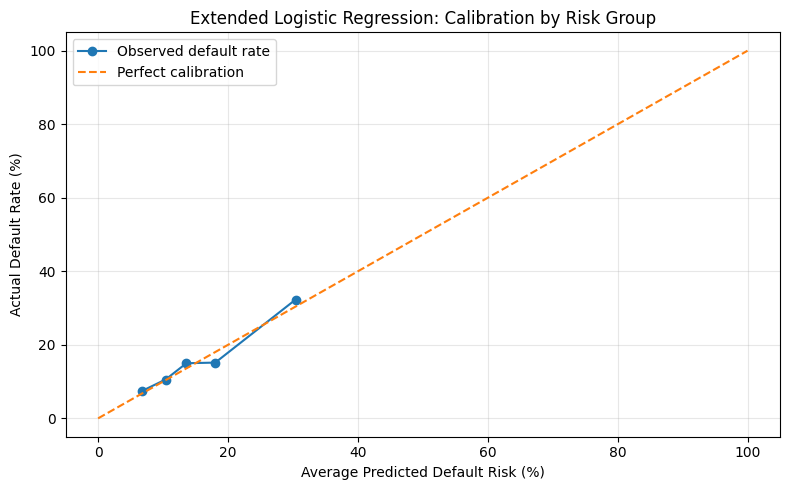

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Create a test-results dataframe
calibration_results = pd.DataFrame({
    "Actual_Default": y_extended_test.to_numpy(),
    "Predicted_Probability": y_extended_test_prob_calibrated
})

# Divide accounts into five groups based on predicted risk
calibration_results["Risk_Group"] = pd.qcut(
    calibration_results["Predicted_Probability"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# Compare predicted and actual default rates
calibration_table = calibration_results.groupby(
    "Risk_Group",
    observed=True
).agg(
    Accounts=("Actual_Default", "size"),
    Actual_Defaults=("Actual_Default", "sum"),
    Actual_Default_Rate=("Actual_Default", "mean"),
    Average_Predicted_Risk=("Predicted_Probability", "mean")
).reset_index()

calibration_table["Actual_Default_Rate"] *= 100
calibration_table["Average_Predicted_Risk"] *= 100

print("CALIBRATION BY RISK GROUP")
display(calibration_table.round(2))

# Plot predicted risk against actual default rate
plt.figure(figsize=(8, 5))
plt.plot(
    calibration_table["Average_Predicted_Risk"],
    calibration_table["Actual_Default_Rate"],
    marker="o",
    label="Observed default rate"
)

plt.plot([0, 100], [0, 100], linestyle="--", label="Perfect calibration")
plt.xlabel("Average Predicted Default Risk (%)")
plt.ylabel("Actual Default Rate (%)")
plt.title("Extended Logistic Regression: Calibration by Risk Group")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "ROC_AUC": 0.6793,
        "Gini": 0.3585,
        "KS": 0.2945,
        "Accuracy": 0.6030,
        "Precision": 0.2447,
        "Recall": 0.7037,
        "F1_Score": 0.3631
    },
    {
        "Model": "Original XGBoost",
        "ROC_AUC": 0.6385,
        "Gini": 0.2769,
        "KS": 0.2329,
        "Accuracy": None,
        "Precision": None,
        "Recall": None,
        "F1_Score": None
    },
    {
        "Model": "Tuned XGBoost",
        "ROC_AUC": 0.6571,
        "Gini": 0.3143,
        "KS": 0.2613,
        "Accuracy": None,
        "Precision": None,
        "Recall": None,
        "F1_Score": None
    },
    {
        "Model": "Extended Logistic Regression",
        "ROC_AUC": 0.6889,
        "Gini": 0.3777,
        "KS": 0.2933,
        "Accuracy": 0.6187,
        "Precision": 0.2490,
        "Recall": 0.6799,
        "F1_Score": 0.3645
    }
])

display(model_comparison.round(4))

,Model,ROC_AUC,Gini,KS,Accuracy,Precision,Recall,F1_Score
0,Baseline Logistic Regression,0.6793,0.3585,0.2945,0.6030,0.2447,0.7037,0.3631
1,Original XGBoost,0.6385,0.2769,0.2329,NaN,NaN,NaN,NaN
2,Tuned XGBoost,0.6571,0.3143,0.2613,NaN,NaN,NaN,NaN
3,Extended Logistic Regression,0.6889,0.3777,0.2933,0.6187,0.2490,0.6799,0.3645


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Use the same threshold as the Logistic Regression comparison
threshold = 0.475

xgb_models = {
    "Original XGBoost": xgb_validation_model,
    "Tuned XGBoost": xgb_tuned_model
}

xgb_results = []

for model_name, model in xgb_models.items():

    # Predict probabilities on validation data
    probabilities = model.predict_proba(X_val)[:, 1]

    # Convert probabilities to class predictions
    predictions = (probabilities >= threshold).astype(int)

    xgb_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1_Score": f1_score(y_val, predictions, zero_division=0)
    })

xgb_validation_comparison = pd.DataFrame(xgb_results)

display(xgb_validation_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score
0,Original XGBoost,0.6604,0.2464,0.5397,0.3383
1,Tuned XGBoost,0.6298,0.2438,0.6190,0.3498


In [48]:
import numpy as np
import pandas as pd

def calculate_psi(reference, comparison, bins=10):
    """
    Calculate Population Stability Index using reference quantile bins.
    """
    reference = np.asarray(reference, dtype=float)
    comparison = np.asarray(comparison, dtype=float)

    # Create bins using the reference distribution
    breakpoints = np.unique(
        np.quantile(reference, np.linspace(0, 1, bins + 1))
    )

    if len(breakpoints) < 3:
        raise ValueError(
            "Insufficient distinct values to create PSI bins."
        )

    # Extend the first and last bins to include all values
    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    reference_counts = np.histogram(
        reference, bins=breakpoints
    )[0]

    comparison_counts = np.histogram(
        comparison, bins=breakpoints
    )[0]

    # Convert counts to proportions and avoid division by zero
    reference_pct = reference_counts / len(reference)
    comparison_pct = comparison_counts / len(comparison)

    epsilon = 1e-6
    reference_pct = np.clip(reference_pct, epsilon, None)
    comparison_pct = np.clip(comparison_pct, epsilon, None)

    psi_values = (
        (comparison_pct - reference_pct)
        * np.log(comparison_pct / reference_pct)
    )

    psi = psi_values.sum()

    distribution_table = pd.DataFrame({
        "Bin": range(1, len(reference_counts) + 1),
        "Reference_Percentage": reference_pct * 100,
        "Comparison_Percentage": comparison_pct * 100,
        "PSI_Contribution": psi_values
    })

    return psi, distribution_table


# Generate calibrated probabilities for the validation set
validation_calibrated_prob = (
    calibrated_extended_model.predict_proba(X_extended_val)[:, 1]
)

# Compare validation and test score distributions
psi_score, psi_table = calculate_psi(
    validation_calibrated_prob,
    y_extended_test_prob_calibrated,
    bins=10
)

print(f"Risk Score PSI: {psi_score:.4f}")

if psi_score < 0.10:
    print("Interpretation: Little distributional change.")
elif psi_score < 0.25:
    print("Interpretation: Moderate distributional change; investigate.")
else:
    print("Interpretation: Substantial distributional change; investigate.")

print("\nRisk score distribution comparison:")
display(psi_table.round(4))

Risk Score PSI: 0.0075
Interpretation: Little distributional change.

Risk score distribution comparison:


,Bin,Reference_Percentage,Comparison_Percentage,PSI_Contribution
0,1,10.0,10.0102,0.0000
1,2,10.0,10.3166,0.0001
2,3,10.0,8.7164,0.0018
3,4,10.0,11.0657,0.0011
4,5,10.0,11.3721,0.0018
5,6,10.0,10.7933,0.0006
6,7,10.0,9.0909,0.0009
7,8,10.0,8.8866,0.0013
8,9,10.0,9.8059,0.0000
9,10,10.0,9.9421,0.0000


In [49]:
import numpy as np
import pandas as pd

def calculate_csi(reference, comparison, bins=10):
    """
    Calculate CSI for a numerical feature using reference quantile bins.
    """
    reference = pd.Series(reference).dropna().to_numpy(dtype=float)
    comparison = pd.Series(comparison).dropna().to_numpy(dtype=float)

    if len(reference) == 0 or len(comparison) == 0:
        return np.nan

    # Define bins using the reference distribution
    breakpoints = np.unique(
        np.quantile(reference, np.linspace(0, 1, bins + 1))
    )

    if len(breakpoints) < 3:
        return np.nan

    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    reference_counts = np.histogram(reference, bins=breakpoints)[0]
    comparison_counts = np.histogram(comparison, bins=breakpoints)[0]

    reference_pct = reference_counts / len(reference)
    comparison_pct = comparison_counts / len(comparison)

    epsilon = 1e-6
    reference_pct = np.clip(reference_pct, epsilon, None)
    comparison_pct = np.clip(comparison_pct, epsilon, None)

    csi = np.sum(
        (comparison_pct - reference_pct)
        * np.log(comparison_pct / reference_pct)
    )

    return csi


# Features to monitor
features_to_monitor = [
    "annual_income",
    "loan_amount",
    "interest_rate_pct",
    "age",
    "bureau_max_days_past_due",
    "avg_days_past_due",
    "late_payments"
]

csi_results = []

for feature in features_to_monitor:
    csi_value = calculate_csi(
        X_extended_val[feature],
        X_extended_test[feature]
    )

    csi_results.append({
        "Feature": feature,
        "CSI": csi_value
    })

csi_table = pd.DataFrame(csi_results).sort_values(
    "CSI", ascending=False
)

def interpret_csi(value):
    if pd.isna(value):
        return "Unable to calculate"
    elif value < 0.10:
        return "Little distributional change"
    elif value < 0.25:
        return "Moderate change; investigate"
    else:
        return "Substantial change; investigate"

csi_table["Interpretation"] = csi_table["CSI"].apply(interpret_csi)

display(csi_table.round(4))

,Feature,CSI,Interpretation
0,annual_income,0.0125,Little distributional change
4,bureau_max_days_past_due,0.0109,Little distributional change
1,loan_amount,0.0060,Little distributional change
3,age,0.0050,Little distributional change
5,avg_days_past_due,0.0033,Little distributional change
2,interest_rate_pct,0.0031,Little distributional change
6,late_payments,0.0003,Little distributional change


Key findings
- Annual income has the highest CSI at 0.0125, but this is still very low.
- Bureau maximum days past due is the next highest at 0.0109.
- Late payments has the lowest CSI at 0.0003, indicating almost identical distributions across the samples.
These results suggest that the selected features have similar distributions in the validation and test sets.

In [50]:
import pandas as pd
import numpy as np

# Create account-level test results
account_risk_scores = pd.DataFrame({
    "account_id": df_combined.loc[X_extended_test.index, "account_id"].values,
    "actual_default": y_extended_test.values,
    "predicted_default_probability": y_extended_test_prob_calibrated
})

# Convert probability into percentage
account_risk_scores["predicted_default_risk_pct"] = (
    account_risk_scores["predicted_default_probability"] * 100
).round(2)

# Assign risk categories based on predicted probability
account_risk_scores["risk_category"] = pd.cut(
    account_risk_scores["predicted_default_probability"],
    bins=[-np.inf, 0.10, 0.20, 0.30, 0.50, np.inf],
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    right=False
)

# Sort highest-risk accounts first
account_risk_scores = account_risk_scores.sort_values(
    "predicted_default_probability",
    ascending=False
).reset_index(drop=True)

# Display sample accounts
print("Total accounts scored:", len(account_risk_scores))
print("\nRisk category summary:")

display(
    account_risk_scores.groupby("risk_category", observed=False)
    .agg(
        Accounts=("account_id", "count"),
        Average_Predicted_Risk=("predicted_default_risk_pct", "mean"),
        Actual_Defaults=("actual_default", "sum")
    )
    .round(2)
)

print("\nTop 10 highest-risk accounts:")
display(account_risk_scores.head(10))

Total accounts scored: 2937

Risk category summary:


,Accounts,Average_Predicted_Risk,Actual_Defaults
risk_category,,,
Very Low,801,7.50,64
Low,1438,14.16,200
Medium,477,24.19,131
High,198,36.99,67
Very High,23,56.83,11



Top 10 highest-risk accounts:


,account_id,actual_default,predicted_default_probability,predicted_default_risk_pct,risk_category
0,ACC212310,1,0.731040,73.10,Very High
1,ACC207443,0,0.688092,68.81,Very High
2,ACC205028,1,0.670153,67.02,Very High
3,ACC201703,1,0.648465,64.85,Very High
4,ACC212372,0,0.610651,61.07,Very High
5,ACC200247,1,0.594052,59.41,Very High
6,ACC212146,0,0.587447,58.74,Very High
7,ACC201905,1,0.580963,58.10,Very High
8,ACC208962,0,0.572105,57.21,Very High
9,ACC204636,0,0.559732,55.97,Very High


Key insights
- Low risk contains the largest number of accounts: 1,438 accounts, or approximately 49% of the test set.
- Medium risk has a 27.46% observed default rate, higher than the Low and Very Low groups.
- High risk has a 33.84% observed default rate, indicating an elevated level of risk.
- Very High risk has the highest average predicted risk, at 56.83%. However, only 23 accounts fall into this category, so the observed default rate of 47.83% should be interpreted cautiously.
The actual default rate does not increase perfectly across all categories: the Very High group has a lower observed default rate than the High group. This is not necessarily a modelling error, particularly given the small Very High group, but it is worth documenting.

These risk bands are illustrative probability ranges rather than established lending-policy thresholds.

,Metric,Value
0,Total Accounts,2937.00
1,Actual Defaults,473.00
2,Actual Default Rate (%),16.10
3,Average Predicted Risk (%),15.85
4,High/Very High Risk Accounts,221.00
5,High/Very High Risk Accounts (%),7.52


,risk_category,Accounts,Average_Predicted_Risk,Account_Percentage
0,Very Low,801,7.50,27.27
1,Low,1438,14.16,48.96
2,Medium,477,24.19,16.24
3,High,198,36.99,6.74
4,Very High,23,56.83,0.78


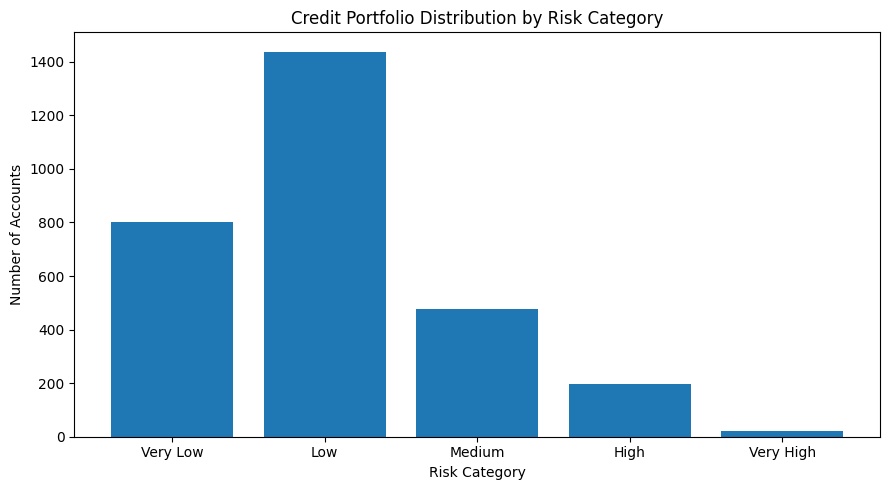

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# Portfolio KPIs based on the current test-set scoring results
total_accounts = len(account_risk_scores)

total_defaults = int(account_risk_scores["actual_default"].sum())

actual_default_rate = (
    total_defaults / total_accounts * 100
)

average_predicted_risk = (
    account_risk_scores["predicted_default_risk_pct"].mean()
)

high_risk_accounts = account_risk_scores[
    account_risk_scores["risk_category"].isin(["High", "Very High"])
].shape[0]

high_risk_percentage = (
    high_risk_accounts / total_accounts * 100
)

portfolio_kpis = pd.DataFrame({
    "Metric": [
        "Total Accounts",
        "Actual Defaults",
        "Actual Default Rate (%)",
        "Average Predicted Risk (%)",
        "High/Very High Risk Accounts",
        "High/Very High Risk Accounts (%)"
    ],
    "Value": [
        total_accounts,
        total_defaults,
        round(actual_default_rate, 2),
        round(average_predicted_risk, 2),
        high_risk_accounts,
        round(high_risk_percentage, 2)
    ]
})

display(portfolio_kpis)

# Account distribution by risk category
risk_distribution = (
    account_risk_scores
    .groupby("risk_category", observed=False)
    .agg(
        Accounts=("account_id", "count"),
        Average_Predicted_Risk=("predicted_default_risk_pct", "mean")
    )
    .reset_index()
)

risk_distribution["Account_Percentage"] = (
    risk_distribution["Accounts"] / total_accounts * 100
)

display(risk_distribution.round(2))

# Plot account distribution
plt.figure(figsize=(9, 5))
plt.bar(
    risk_distribution["risk_category"].astype(str),
    risk_distribution["Accounts"]
)
plt.xlabel("Risk Category")
plt.ylabel("Number of Accounts")
plt.title("Credit Portfolio Distribution by Risk Category")
plt.tight_layout()
plt.show()

In [52]:
# Create an account-level dataset for the credit risk dashboard

dashboard_columns = [
    "account_id",
    "customer_id",
    "loan_type",
    "loan_purpose",
    "loan_amount",
    "interest_rate_pct",
    "tenure_months",
    "annual_income",
    "employment_type",
    "age",
    "total_bureau_outstanding",
    "bureau_max_days_past_due",
    "active_bureau_accounts",
    "late_payments",
    "avg_days_past_due",
    "repayment_max_days_past_due",
    "highest_outstanding_balance",
    "emi_shortfall"
]

# Keep only columns available in the combined dataset
available_columns = [
    col for col in dashboard_columns
    if col in df_combined.columns
]

# Match account details to the accounts scored in the test set
dashboard_accounts = (
    df_combined.loc[
        df_combined["account_id"].isin(account_risk_scores["account_id"]),
        available_columns
    ]
    .drop_duplicates(subset="account_id")
)

# Add predicted risk and risk category
dashboard_accounts = dashboard_accounts.merge(
    account_risk_scores[
        [
            "account_id",
            "predicted_default_risk_pct",
            "risk_category"
        ]
    ],
    on="account_id",
    how="inner",
    validate="one_to_one"
)

# Sort highest-risk accounts first
dashboard_accounts = dashboard_accounts.sort_values(
    "predicted_default_risk_pct",
    ascending=False
).reset_index(drop=True)

print("Dashboard dataset shape:", dashboard_accounts.shape)
print("\nRisk category distribution:")
display(
    dashboard_accounts["risk_category"]
    .value_counts()
    .reindex(["Very Low", "Low", "Medium", "High", "Very High"])
    .rename("Number of Accounts")
    .to_frame()
)

print("\nTop 10 highest-risk accounts:")
display(dashboard_accounts.head(10))

Dashboard dataset shape: (2937, 20)

Risk category distribution:


,Number of Accounts
risk_category,
Very Low,801
Low,1438
Medium,477
High,198
Very High,23



Top 10 highest-risk accounts:


,account_id,customer_id,loan_type,loan_purpose,loan_amount,interest_rate_pct,tenure_months,annual_income,employment_type,age,total_bureau_outstanding,bureau_max_days_past_due,active_bureau_accounts,late_payments,avg_days_past_due,repayment_max_days_past_due,highest_outstanding_balance,emi_shortfall,predicted_default_risk_pct,risk_category
0,ACC212310,CUST108342,Mortgage,Education,306413.17,5.37,360,12000,Unemployed,25,25283.17,49.0,1.0,3,10.916667,43,305384.25,3429.74,73.10,Very High
1,ACC207443,CUST105070,Auto Loan,Business Expansion,25180.65,8.77,36,12000,Unemployed,33,14200.99,48.0,1.0,6,21.666667,69,25180.65,2394.15,68.81,Very High
2,ACC205028,CUST103438,Mortgage,Medical,377326.85,6.67,180,38100,Unemployed,35,0.00,0.0,0.0,5,4.750000,23,375349.72,0.00,67.02,Very High
3,ACC201703,CUST101171,Mortgage,Other,279844.19,4.70,180,13600,Salaried,21,19299.72,24.0,1.0,2,16.333333,75,278542.49,6508.50,64.85,Very High
4,ACC212372,CUST108380,Auto Loan,Business Expansion,25035.25,8.17,36,27500,Business Owner,21,42452.32,67.0,0.0,1,27.416667,83,24563.36,3145.92,61.07,Very High
5,ACC200247,CUST100169,Mortgage,Debt Consolidation,352385.33,5.65,240,83000,Salaried,38,19718.86,58.0,2.0,4,20.500000,82,352385.33,4907.92,59.41,Very High
6,ACC212146,CUST108220,Credit Card,Medical,10388.59,23.52,12,12000,Unemployed,24,30142.67,58.0,1.0,2,10.833333,81,9800.63,979.93,58.74,Very High
7,ACC201905,CUST101311,Mortgage,Vehicle Purchase,247903.68,7.04,360,79100,Unemployed,47,42509.08,39.0,1.0,3,22.333333,88,246910.10,4967.91,58.10,Very High
8,ACC208962,CUST106074,Business Loan,Vehicle Purchase,41942.80,9.59,36,33100,Unemployed,39,160.15,26.0,0.0,6,13.166667,45,41135.61,1345.32,57.21,Very High
9,ACC204636,CUST103164,Personal Loan,Wedding,18944.37,11.28,36,14000,Unemployed,31,33850.07,54.0,4.0,2,13.333333,72,18570.73,1245.46,55.97,Very High


In [53]:
import numpy as np
import pandas as pd

# Retrieve the fitted preprocessing pipeline and Logistic Regression model
preprocessor = extended_logistic_model.named_steps["preprocessor"]
classifier = extended_logistic_model.named_steps["classifier"]

# Transform test accounts into the feature representation used by the model
X_test_transformed = preprocessor.transform(X_extended_test)

# Get transformed feature names and model coefficients
feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

# Calculate each feature's contribution to the Logistic Regression score
if hasattr(X_test_transformed, "toarray"):
    X_test_array = X_test_transformed.toarray()
else:
    X_test_array = np.asarray(X_test_transformed)

contributions = X_test_array * coefficients

# Create a table of contributions for each account
contribution_df = pd.DataFrame(
    contributions,
    columns=feature_names,
    index=X_extended_test.index
)

# Match the account IDs to the original test rows
contribution_df["account_id"] = df_combined.loc[
    X_extended_test.index, "account_id"
].values

# Convert to a long format for identifying the largest contributions
contribution_long = contribution_df.melt(
    id_vars="account_id",
    var_name="Model_Feature",
    value_name="Contribution"
)

# Keep the five strongest positive and five strongest negative
# contributions for each account
contribution_long["Direction"] = np.where(
    contribution_long["Contribution"] > 0,
    "Pushes score toward default",
    "Pushes score away from default"
)

top_contributions = (
    contribution_long
    .assign(Abs_Contribution=lambda x: x["Contribution"].abs())
    .sort_values(
        ["account_id", "Abs_Contribution"],
        ascending=[True, False]
    )
    .groupby("account_id")
    .head(5)
    .reset_index(drop=True)
)

print("Number of accounts with calculated contributions:",
      top_contributions["account_id"].nunique())

print("\nLargest model contributions for the highest-risk account:")
highest_risk_account = account_risk_scores.iloc[0]["account_id"]

display(
    top_contributions[
        top_contributions["account_id"] == highest_risk_account
    ][
        ["account_id", "Model_Feature", "Contribution", "Direction"]
    ]
)

Number of accounts with calculated contributions: 2937

Largest model contributions for the highest-risk account:


,account_id,Model_Feature,Contribution,Direction
12250,ACC212310,numeric__highest_outstanding_balance,0.694557,Pushes score toward default
12251,ACC212310,numeric__annual_income,0.677463,Pushes score toward default
12252,ACC212310,numeric__loan_amount,0.653798,Pushes score toward default
12253,ACC212310,numeric__avg_days_past_due,0.300239,Pushes score toward default
12254,ACC212310,categorical__employment_type_Unemployed,0.288529,Pushes score toward default


In [54]:
# Create account-level explanation data for the dashboard

# Separate positive and negative contributions
positive_contributions = contribution_long[
    contribution_long["Contribution"] > 0
].copy()

negative_contributions = contribution_long[
    contribution_long["Contribution"] < 0
].copy()

# Top 3 factors pushing the score toward default
top_positive = (
    positive_contributions
    .sort_values(
        ["account_id", "Contribution"],
        ascending=[True, False]
    )
    .groupby("account_id")
    .head(3)
)

top_positive["Rank"] = (
    top_positive.groupby("account_id")["Contribution"]
    .rank(method="first", ascending=False)
    .astype(int)
)

positive_wide = top_positive.pivot(
    index="account_id",
    columns="Rank",
    values="Model_Feature"
).rename(columns={
    1: "Risk_Driver_1",
    2: "Risk_Driver_2",
    3: "Risk_Driver_3"
})

# Top 3 factors pushing the score away from default
top_negative = (
    negative_contributions
    .sort_values(
        ["account_id", "Contribution"],
        ascending=[True, True]
    )
    .groupby("account_id")
    .head(3)
)

top_negative["Rank"] = (
    top_negative.groupby("account_id")["Contribution"]
    .rank(method="first", ascending=True)
    .astype(int)
)

negative_wide = top_negative.pivot(
    index="account_id",
    columns="Rank",
    values="Model_Feature"
).rename(columns={
    1: "Protective_Factor_1",
    2: "Protective_Factor_2",
    3: "Protective_Factor_3"
})

# Combine risk scores and model contribution summaries
account_explanations = (
    account_risk_scores[
        [
            "account_id",
            "predicted_default_risk_pct",
            "risk_category"
        ]
    ]
    .set_index("account_id")
    .join(positive_wide)
    .join(negative_wide)
    .reset_index()
)

# Add account details for dashboard filtering and drill-down
account_explanations = account_explanations.merge(
    dashboard_accounts.drop(
        columns=[
            "predicted_default_risk_pct",
            "risk_category"
        ]
    ),
    on="account_id",
    how="left",
    validate="one_to_one"
)

print("Explanation dataset shape:", account_explanations.shape)

print("\nHighest-risk account explanation:")
display(
    account_explanations[
        account_explanations["account_id"] == highest_risk_account
    ].T
)

print("\nMissing values in explanation columns:")
display(
    account_explanations[
        [
            "Risk_Driver_1",
            "Risk_Driver_2",
            "Risk_Driver_3",
            "Protective_Factor_1",
            "Protective_Factor_2",
            "Protective_Factor_3"
        ]
    ].isna().sum().to_frame("Missing_Count")
)

Explanation dataset shape: (2937, 26)

Highest-risk account explanation:


,0
account_id,ACC212310
predicted_default_risk_pct,73.1
risk_category,Very High
Risk_Driver_1,numeric__highest_outstanding_balance
Risk_Driver_2,numeric__annual_income
Risk_Driver_3,numeric__loan_amount
Protective_Factor_1,numeric__interest_rate_pct
Protective_Factor_2,categorical__loan_type_Mortgage
Protective_Factor_3,categorical__loan_purpose_Education
customer_id,CUST108342



Missing values in explanation columns:


,Missing_Count
Risk_Driver_1,0
Risk_Driver_2,0
Risk_Driver_3,0
Protective_Factor_1,0
Protective_Factor_2,0
Protective_Factor_3,0


In [55]:
import pandas as pd
from IPython.display import display

# 1. Export account-level risk scores
account_risk_scores.to_csv(
    "account_risk_scores.csv",
    index=False
)

# 2. Export account details and model explanations
account_explanations.to_csv(
    "account_risk_explanations.csv",
    index=False
)

# 3. Create and export the portfolio KPI summary
total_accounts = len(account_risk_scores)
total_defaults = int(account_risk_scores["actual_default"].sum())

portfolio_summary = pd.DataFrame({
    "Metric": [
        "Total Accounts",
        "Actual Defaults",
        "Actual Default Rate (%)",
        "Average Predicted Risk (%)",
        "High and Very High Risk Accounts",
        "High and Very High Risk Accounts (%)"
    ],
    "Value": [
        total_accounts,
        total_defaults,
        round(
            account_risk_scores["actual_default"].mean() * 100, 2
        ),
        round(
            account_risk_scores["predicted_default_risk_pct"].mean(), 2
        ),
        int(
            account_risk_scores["risk_category"]
            .isin(["High", "Very High"]).sum()
        ),
        round(
            account_risk_scores["risk_category"]
            .isin(["High", "Very High"]).mean() * 100, 2
        )
    ]
})

portfolio_summary.to_csv(
    "portfolio_summary.csv",
    index=False
)

print("Exported files:")
print("1. account_risk_scores.csv")
print("2. account_risk_explanations.csv")
print("3. portfolio_summary.csv")

print("\nPortfolio summary:")
display(portfolio_summary)

Exported files:
1. account_risk_scores.csv
2. account_risk_explanations.csv
3. portfolio_summary.csv

Portfolio summary:


,Metric,Value
0,Total Accounts,2937.00
1,Actual Defaults,473.00
2,Actual Default Rate (%),16.10
3,Average Predicted Risk (%),15.85
4,High and Very High Risk Accounts,221.00
5,High and Very High Risk Accounts (%),7.52


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/CRA_combined.csv"
)

In [57]:
df["exposure"] = df["loan_amount"]

total_exposure = df["exposure"].sum()

print("Total original exposure:", total_exposure)

Total original exposure: 601119531.64


In [58]:
def segment_profile(data, group_cols):

    result = (
        data.groupby(group_cols, dropna=False)
        .agg(
            accounts=("account_id", "count"),
            defaults=("target_default", "sum"),
            exposure=("exposure", "sum")
        )
        .reset_index()
    )

    result["default_rate"] = (
        result["defaults"] / result["accounts"] * 100
    )

    result["exposure_share"] = (
        result["exposure"]
        / data["exposure"].sum() * 100
    )

    return result

In [59]:
loan_profile = segment_profile(df, ["loan_type"])

display(
    loan_profile.sort_values(
        "default_rate", ascending=False
    )
)

,loan_type,accounts,defaults,exposure,default_rate,exposure_share
3,Mortgage,1432,353,3.144738e+08,24.650838,52.314679
2,Credit Card,3721,603,3.001684e+07,16.205321,4.993490
1,Business Loan,1484,238,9.901763e+07,16.037736,16.472203
4,Personal Loan,5216,777,7.881549e+07,14.896472,13.111451
0,Auto Loan,2832,393,7.879581e+07,13.877119,13.108177


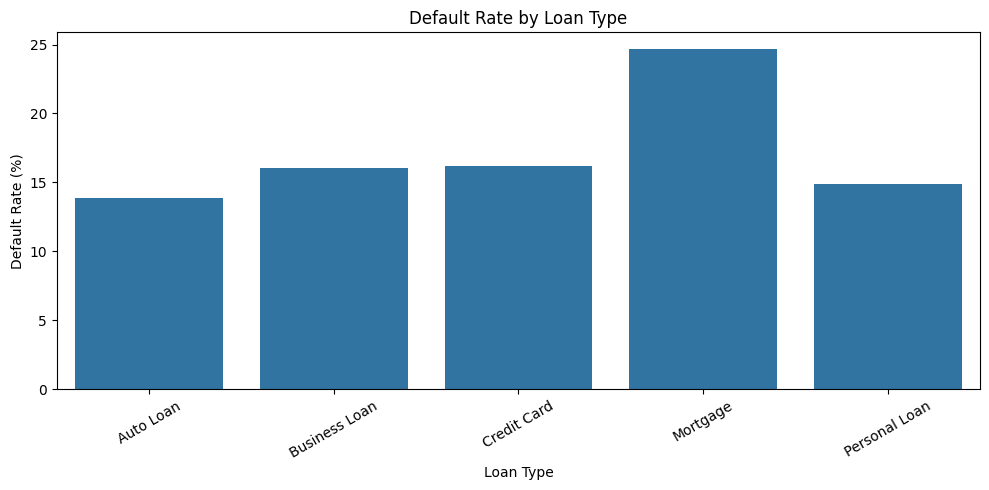

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=loan_profile,
    x="loan_type",
    y="default_rate"
)

plt.title("Default Rate by Loan Type")
plt.xlabel("Loan Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [61]:
employment_profile = segment_profile(
    df, ["employment_type"]
)

display(employment_profile)

,employment_type,accounts,defaults,exposure,default_rate,exposure_share
0,Business Owner,1844,250,7.351125e+07,13.557484,12.229057
1,Contract,1563,271,6.159217e+07,17.338452,10.246244
2,Salaried,7546,1130,3.130173e+08,14.974821,52.072397
3,Self-Employed,3014,462,1.233732e+08,15.328467,20.523911
4,Unemployed,718,251,2.962552e+07,34.958217,4.928391


In [62]:
df["income_band"] = pd.cut(
    df["annual_income"],
    bins=[0, 25000, 50000, 100000, 200000, np.inf],
    labels=[
        "0-25k",
        "25k-50k",
        "50k-100k",
        "100k-200k",
        "200k+"
    ]
)

income_profile = segment_profile(
    df, ["income_band"]
)

display(income_profile)

/tmp/ipykernel_1032/725901463.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(group_cols, dropna=False)


,income_band,accounts,defaults,exposure,default_rate,exposure_share
0,0-25k,321,127,1.226252e+07,39.563863,2.039948
1,25k-50k,1527,389,6.460270e+07,25.474787,10.747064
2,50k-100k,9761,1555,4.003371e+08,15.930745,66.598582
3,100k-200k,3076,293,1.239172e+08,9.525358,20.614406
4,200k+,0,0,0.000000e+00,NaN,0.000000


In [63]:
region_profile = segment_profile(
    df, ["region"]
)

df["age_band"] = pd.cut(
    df["age"],
    bins=[18, 25, 35, 45, 55, np.inf],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ],
    include_lowest=True
)

age_profile = segment_profile(
    df, ["age_band"]
)

display(region_profile)
display(age_profile)

/tmp/ipykernel_1032/725901463.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(group_cols, dropna=False)


,region,accounts,defaults,exposure,default_rate,exposure_share
0,Central,2314,347,9.631142e+07,14.995678,16.022008
1,East,2747,440,1.082062e+08,16.017474,18.000782
2,North,3147,515,1.294322e+08,16.364792,21.531860
3,South,3600,607,1.562678e+08,16.861111,25.996133
4,West,2877,455,1.109018e+08,15.815085,18.449216


,age_band,accounts,defaults,exposure,default_rate,exposure_share
0,18-25,1927,427,8.423725e+07,22.158796,14.013394
1,26-35,4070,751,1.711646e+08,18.452088,28.474298
2,36-45,5097,775,2.026151e+08,15.205023,33.706284
3,46-55,2758,323,1.074517e+08,11.711385,17.875264
4,56+,833,88,3.565096e+07,10.564226,5.930760


/tmp/ipykernel_1032/725901463.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(group_cols, dropna=False)


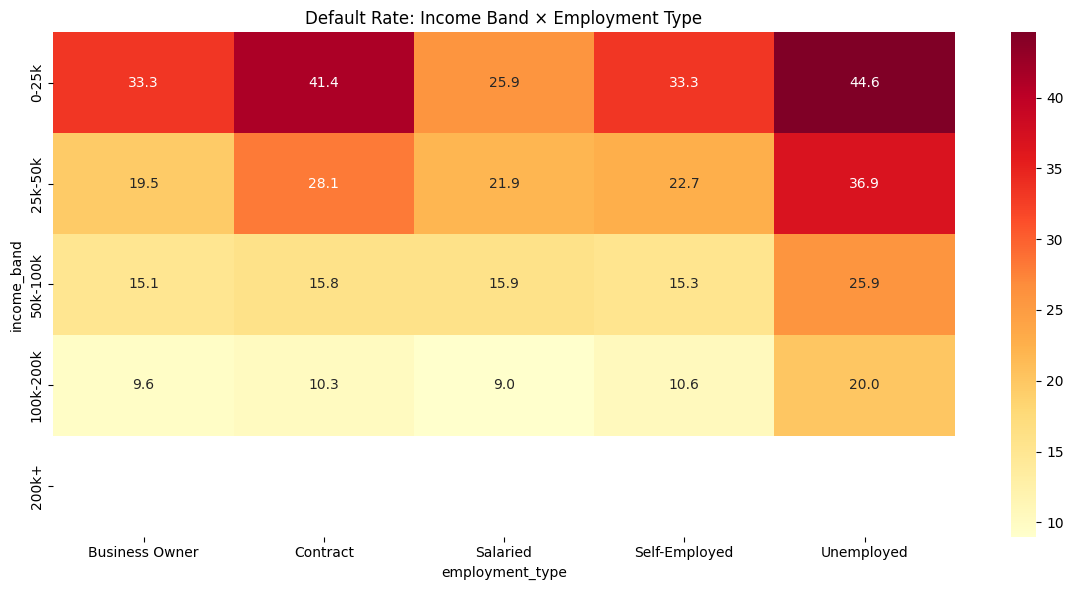

In [64]:
cross_profile = segment_profile(
    df,
    ["income_band", "employment_type"]
)

pivot = cross_profile.pivot(
    index="income_band",
    columns="employment_type",
    values="default_rate"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title(
    "Default Rate: Income Band × Employment Type"
)

plt.tight_layout()
plt.show()

In [65]:
# Re-create engineered features on the newly loaded df
df["emi_shortfall"] = df["total_emi_due"] - df["total_emi_paid"]

numeric_features = [
    "age",
    "annual_income",
    "years_employed",
    "loan_amount",
    "interest_rate_pct",
    "tenure_months",
    "avg_days_past_due",
    "repayment_max_days_past_due",
    "late_payments",
    "emi_shortfall"
]

categorical_features = [
    "employment_type",
    "region",
    "loan_type"
]

X = df[numeric_features + categorical_features]

y = df["target_default"]

In [66]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=df["customer_id"]
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training accounts:", len(X_train))
print("Testing accounts:", len(X_test))

Training accounts: 11737
Testing accounts: 2948


In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [68]:
logistic_model.fit(X_train, y_train)

y_probability = logistic_model.predict_proba(
    X_test
)[:, 1]

In [69]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

auc = roc_auc_score(
    y_test, y_probability
)

fpr, tpr, thresholds = roc_curve(
    y_test, y_probability
)

ks = np.max(tpr - fpr)

gini = 2 * auc - 1

print(f"AUC: {auc:.4f}")
print(f"KS: {ks:.4f}")
print(f"Gini: {gini:.4f}")

AUC: 0.6806
KS: 0.2676
Gini: 0.3612


In [70]:
import joblib
import os

# Ensure the target directory exists before saving
os.makedirs("../models", exist_ok=True)

joblib.dump(
    logistic_model,
    "../models/logistic_baseline.pkl"
)

['../models/logistic_baseline.pkl']

In [71]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# Correcting the file path to point to the actual file location
df = pd.read_csv(
    "/content/CRA_combined.csv"
)

print("Dataset shape:", df.shape)
print("Unique accounts:", df["account_id"].nunique())
print("Default rate:", df["target_default"].mean())

assert len(df) == 14685
assert df["account_id"].is_unique

Dataset shape: (14685, 42)
Unique accounts: 14685
Default rate: 0.1609805924412666


In [72]:
from sklearn.model_selection import GroupShuffleSplit

# Re-engineer the emi_shortfall feature in case it isn't in df
df["emi_shortfall"] = df["total_emi_due"] - df["total_emi_paid"]

# Map to the correct columns that actually exist in the dataframe
numeric_features = [
    "annual_income",
    "years_employed",
    "loan_amount",
    "interest_rate_pct",
    "tenure_months",
    "avg_days_past_due",
    "repayment_max_days_past_due",
    "late_payments",
    "emi_shortfall"
]

categorical_features = [
    "employment_type",
    "loan_type"
]

features = numeric_features + categorical_features

X = df[features]
y = df["target_default"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X, y, groups=df["customer_id"]
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [74]:
logistic_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

lr_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

xgb_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

In [75]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss
)

def evaluate_model(name, actual, probability):
    auc = roc_auc_score(actual, probability)
    fpr, tpr, _ = roc_curve(actual, probability)

    return {
        "Model": name,
        "AUC": auc,
        "KS": np.max(tpr - fpr),
        "Gini": 2 * auc - 1,
        "Brier": brier_score_loss(
            actual, probability
        )
    }

results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, lr_prob
    ),
    evaluate_model(
        "XGBoost", y_test, xgb_prob
    )
])

display(results.round(4))

,Model,AUC,KS,Gini,Brier
0,Logistic Regression,0.6800,0.2694,0.3600,0.1251
1,XGBoost,0.6596,0.2613,0.3193,0.1274


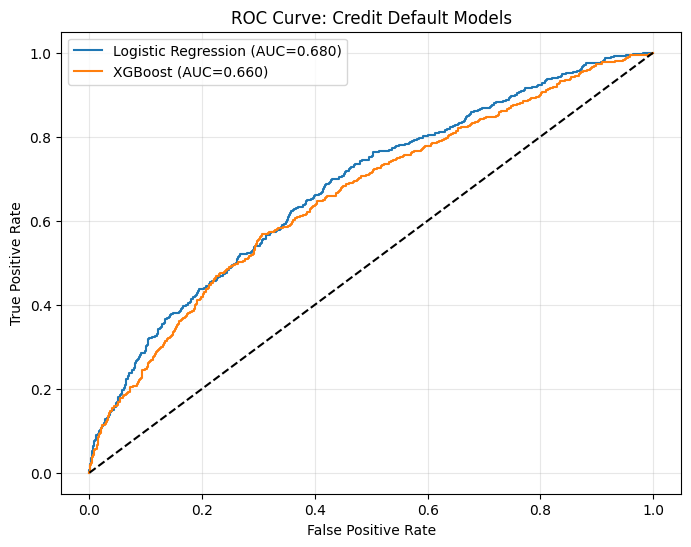

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, prob in [
    ("Logistic Regression", lr_prob),
    ("XGBoost", xgb_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Credit Default Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [77]:
from pathlib import Path
import joblib

# Ensure target directories exist before saving
Path("../models").mkdir(parents=True, exist_ok=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

# Save the models
joblib.dump(
    logistic_model,
    "../models/logistic_baseline.pkl"
)

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

# Save the model metrics
results.to_csv(
    "../data/processed/model_metrics.csv",
    index=False
)

# Prepare and save test set predictions
test_predictions = df.iloc[test_idx][[
    "account_id", "customer_id", "target_default"
]].copy()

test_predictions["lr_probability"] = lr_prob
test_predictions["xgb_probability"] = xgb_prob

test_predictions.to_csv(
    "../data/processed/test_predictions.csv",
    index=False
)

In [78]:
feature_names = (
    xgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": (
        xgb_model.named_steps["classifier"]
        .feature_importances_
    )
})

importance = importance.sort_values(
    "importance", ascending=False
)

display(importance.head(15))

,feature,importance
13,cat__employment_type_Unemployed,0.204427
17,cat__loan_type_Mortgage,0.094665
0,num__annual_income,0.091533
5,num__avg_days_past_due,0.077216
7,num__late_payments,0.063569
1,num__years_employed,0.055733
2,num__loan_amount,0.046365
6,num__repayment_max_days_past_due,0.044357
8,num__emi_shortfall,0.040585
14,cat__loan_type_Auto Loan,0.038966


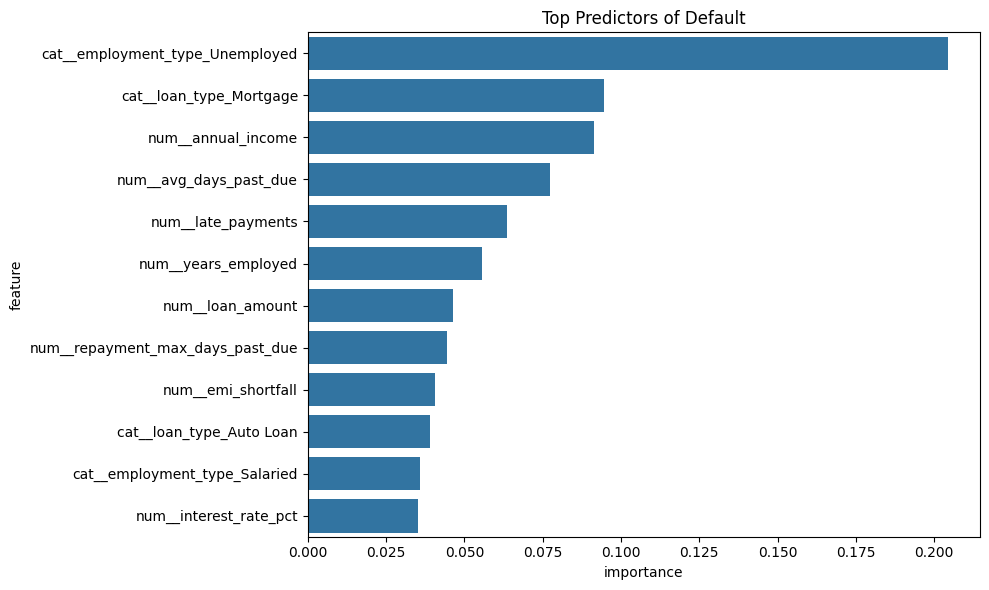

In [79]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(12),
    x="importance",
    y="feature"
)

plt.title("Top Predictors of Default")
plt.tight_layout()
plt.show()

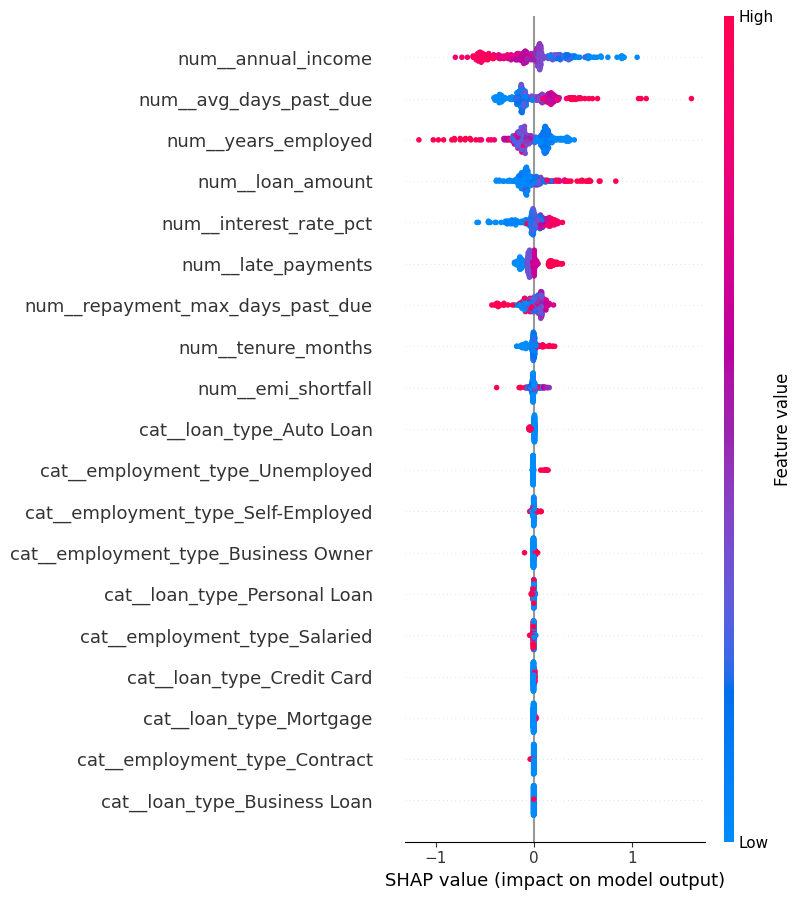

In [80]:
import shap

transformer = xgb_model.named_steps["preprocessor"]
classifier = xgb_model.named_steps["classifier"]

X_sample = X_test.iloc[:300]

X_transformed = transformer.transform(X_sample)

explainer = shap.TreeExplainer(classifier)

shap_values = explainer(
    X_transformed
)

shap.summary_plot(
    shap_values.values,
    X_transformed,
    feature_names=feature_names
)

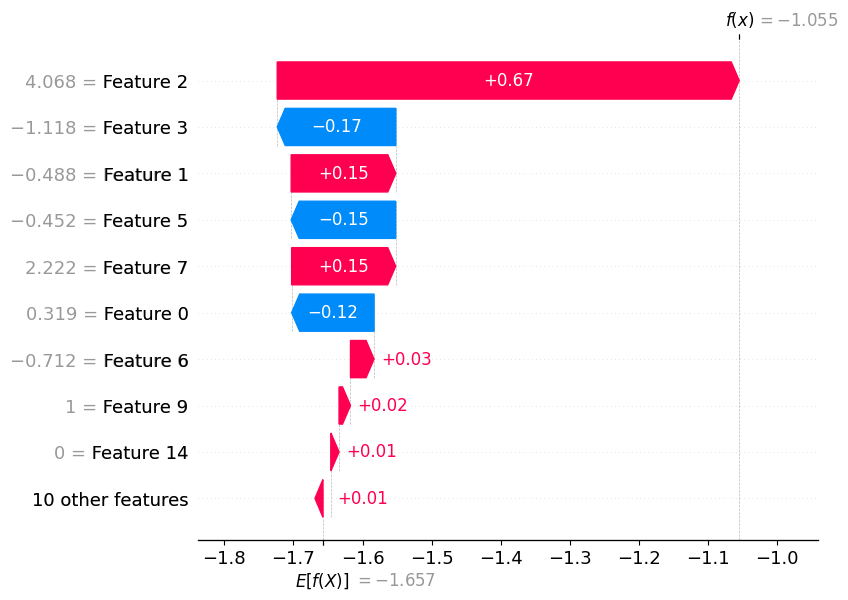

In [81]:
shap.plots.waterfall(shap_values[0])

In [82]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Reuse the existing dataset, or load it
if "df_combined" in globals():
    df = df_combined.copy()
elif "df" in globals():
    df = df.copy()
else:
    df = pd.read_csv("/content/CRA_combined.csv")

# Create an engineered repayment feature
df["emi_shortfall"] = df["total_emi_due"] - df["total_emi_paid"]

# Features used to identify unusual account patterns
anomaly_features = [
    "loan_amount",
    "interest_rate_pct",
    "annual_income",
    "total_bureau_outstanding",
    "bureau_max_days_past_due",
    "active_bureau_accounts",
    "late_payments",
    "repayment_max_days_past_due",
    "avg_days_past_due",
    "total_emi_due",
    "total_emi_paid",
    "highest_outstanding_balance",
    "emi_shortfall"
]

# Prepare numeric data and fill missing values
anomaly_input = df[anomaly_features].copy()
anomaly_input = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(anomaly_input),
    columns=anomaly_features,
    index=df.index
)

print("Accounts prepared:", len(anomaly_input))
print("Features used:", len(anomaly_features))
print("Missing values remaining:", anomaly_input.isna().sum().sum())

Accounts prepared: 14685
Features used: 13
Missing values remaining: 0


In [83]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Standardise features
scaler = StandardScaler()
anomaly_scaled = scaler.fit_transform(anomaly_input)

# Train Isolation Forest
anomaly_model = IsolationForest(
    n_estimators=100,
    contamination=0.03,
    random_state=42
)

anomaly_model.fit(anomaly_scaled)

# Flag unusual accounts and calculate anomaly scores
df["anomaly_flag"] = anomaly_model.predict(anomaly_scaled)
df["anomaly_score"] = -anomaly_model.decision_function(anomaly_scaled)

# Summarise results
print("Total accounts:", len(df))
print("Flagged anomalies:", (df["anomaly_flag"] == -1).sum())
print("Normal accounts:", (df["anomaly_flag"] == 1).sum())

Total accounts: 14685
Flagged anomalies: 441
Normal accounts: 14244


In [84]:
# Select accounts flagged as unusual
anomalies = df[df["anomaly_flag"] == -1].copy()

# Show the most unusual accounts first
review_columns = [
    "account_id",
    "loan_type",
    "loan_amount",
    "annual_income",
    "bureau_max_days_past_due",
    "late_payments",
    "repayment_max_days_past_due",
    "avg_days_past_due",
    "emi_shortfall",
    "anomaly_score"
]

review_columns = [
    col for col in review_columns if col in anomalies.columns
]

print("Flagged accounts:", len(anomalies))
print("\nTop 10 most unusual accounts:")

display(
    anomalies[review_columns]
    .sort_values("anomaly_score", ascending=False)
    .head(10)
    .round(2)
)

Flagged accounts: 441

Top 10 most unusual accounts:


,account_id,loan_type,loan_amount,annual_income,bureau_max_days_past_due,late_payments,repayment_max_days_past_due,avg_days_past_due,emi_shortfall,anomaly_score
5447,ACC205448,Mortgage,401482.90,58800,35.0,3,64,15.08,6124.58,0.11
1968,ACC201969,Mortgage,337399.71,105000,31.0,4,85,29.42,11263.40,0.11
1554,ACC201555,Mortgage,312500.01,75000,48.0,5,84,23.83,9608.88,0.11
5027,ACC205028,Mortgage,377326.85,38100,0.0,5,23,4.75,0.00,0.10
12012,ACC212013,Business Loan,124341.82,121000,37.0,4,81,20.17,16930.53,0.10
12376,ACC212377,Mortgage,344775.54,51400,44.0,0,0,0.00,0.00,0.10
246,ACC200247,Mortgage,352385.33,83000,58.0,4,82,20.50,4907.92,0.10
8000,ACC208001,Business Loan,94163.21,57400,59.0,2,65,18.67,17338.92,0.10
3221,ACC203222,Mortgage,276360.79,12000,46.0,5,56,15.50,4964.92,0.10
2883,ACC202884,Business Loan,112190.38,12000,47.0,1,84,11.33,10237.40,0.09


In [85]:
# Prepare anomaly results for the dashboard
anomaly_results = df[
    ["account_id"] + anomaly_features +
    ["anomaly_flag", "anomaly_score"]
].copy()

anomaly_results["anomaly_status"] = anomaly_results[
    "anomaly_flag"
].map({
    -1: "Flagged as Unusual",
    1: "Normal"
})

# Show unusual accounts first
anomaly_results = anomaly_results.sort_values(
    "anomaly_score", ascending=False
).reset_index(drop=True)

# Save to Colab
anomaly_results.to_csv(
    "/content/anomaly_results.csv",
    index=False
)

print("Dataset shape:", anomaly_results.shape)
print("\nAnomaly status summary:")
display(anomaly_results["anomaly_status"].value_counts().to_frame("Accounts"))

print("\nSaved: /content/anomaly_results.csv")

Dataset shape: (14685, 17)

Anomaly status summary:


,Accounts
anomaly_status,
Normal,14244
Flagged as Unusual,441



Saved: /content/anomaly_results.csv


In [86]:
!pip -q install streamlit plotly

In [87]:
print("XGBoost model exists:", "xgb_model" in globals())
print("Features exist:", "features" in globals())

if "features" in globals():
    print("Number of features:", len(features))
    print("Missing columns:", [
        col for col in features if col not in df.columns
    ])

XGBoost model exists: True
Features exist: True
Number of features: 11
Missing columns: []


In [88]:
# Prepare portfolio risk scores
dashboard_df = df.copy()

dashboard_df["risk_probability"] = xgb_model.predict_proba(
    dashboard_df[features]
)[:, 1]

dashboard_df["risk_segment"] = pd.cut(
    dashboard_df["risk_probability"],
    bins=[-0.001, 0.10, 0.25, 1.0],
    labels=["Low", "Medium", "High"]
)

# Save the dashboard dataset in Colab
dashboard_df.to_csv(
    "/content/dashboard_portfolio.csv",
    index=False
)

print("Dataset shape:", dashboard_df.shape)
print("\nRisk segment counts:")
display(dashboard_df["risk_segment"].value_counts(dropna=False))

print("\nPredicted probability range:")
print(
    round(dashboard_df["risk_probability"].min(), 4),
    "to",
    round(dashboard_df["risk_probability"].max(), 4)
)

print("\nSaved: /content/dashboard_portfolio.csv")

Dataset shape: (14685, 47)

Risk segment counts:


,count
risk_segment,
Medium,8628
Low,4057
High,2000



Predicted probability range:
0.0174 to 0.822

Saved: /content/dashboard_portfolio.csv


In [89]:
!pip -q install streamlit plotly

In [90]:
%%writefile /content/app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Credit Risk Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("Credit Risk Analytics Dashboard")
st.caption("Portfolio risk overview and unusual account detection")

# Load the prepared datasets
portfolio = pd.read_csv("/content/dashboard_portfolio.csv")
anomalies = pd.read_csv("/content/anomaly_results.csv")

# Combine risk scores with anomaly results
data = portfolio.merge(
    anomalies[["account_id", "anomaly_flag", "anomaly_score",
               "anomaly_status"]],
    on="account_id",
    how="left",
    validate="one_to_one"
)

data["risk_pct"] = data["risk_probability"] * 100

# Sidebar filters
st.sidebar.header("Dashboard Filters")

risk_options = sorted(data["risk_segment"].dropna().astype(str).unique())
selected_risks = st.sidebar.multiselect(
    "Risk segment",
    risk_options,
    default=risk_options
)

anomaly_choice = st.sidebar.selectbox(
    "Anomaly status",
    ["All accounts", "Flagged as Unusual", "Normal"]
)

filtered = data[data["risk_segment"].astype(str).isin(selected_risks)]

if anomaly_choice != "All accounts":
    filtered = filtered[filtered["anomaly_status"] == anomaly_choice]

# Portfolio KPIs
c1, c2, c3, c4 = st.columns(4)

c1.metric("Accounts", f"{len(filtered):,}")
c2.metric("Average Predicted Risk", f"{filtered['risk_pct'].mean():.2f}%")
c3.metric("High-Risk Accounts", f"{(filtered['risk_segment'].astype(str) == 'High').sum():,}")
c4.metric("Flagged Anomalies", f"{(filtered['anomaly_flag'] == -1).sum():,}")

st.divider()

# Risk distribution
left, right = st.columns(2)

with left:
    st.subheader("Accounts by Risk Segment")
    risk_counts = (
        filtered["risk_segment"].astype(str)
        .value_counts()
        .reindex(["Low", "Medium", "High"], fill_value=0)
        .rename_axis("Risk Segment")
        .reset_index(name="Accounts")
    )
    fig = px.bar(
        risk_counts,
        x="Risk Segment",
        y="Accounts",
        color="Risk Segment",
        title="Portfolio Risk Distribution"
    )
    st.plotly_chart(fig, use_container_width=True)

with right:
    st.subheader("Anomaly Detection")
    anomaly_counts = (
        filtered["anomaly_status"]
        .value_counts()
        .rename_axis("Status")
        .reset_index(name="Accounts")
    )
    fig2 = px.pie(
        anomaly_counts,
        names="Status",
        values="Accounts",
        title="Normal vs Unusual Accounts"
    )
    st.plotly_chart(fig2, use_container_width=True)

# Account-level explorer
st.divider()
st.subheader("Account Explorer")

if not filtered.empty:
    account_ids = filtered["account_id"].astype(str).tolist()
    selected_account = st.selectbox("Select an account", account_ids)

    account = filtered[
        filtered["account_id"].astype(str) == selected_account
    ].iloc[0]

    c1, c2, c3 = st.columns(3)
    c1.metric("Predicted Default Risk", f"{account['risk_pct']:.2f}%")
    c2.metric("Risk Segment", str(account["risk_segment"]))
    c3.metric("Anomaly Status", str(account["anomaly_status"]))

    st.write("**Account details**")
    detail_columns = [
        col for col in [
            "account_id", "loan_type", "loan_amount", "annual_income",
            "employment_type", "bureau_max_days_past_due",
            "late_payments", "repayment_max_days_past_due",
            "emi_shortfall", "anomaly_score"
        ]
        if col in account.index
    ]
    st.dataframe(
        account[detail_columns].to_frame("Value"),
        use_container_width=True
    )

    if account["anomaly_flag"] == -1:
        st.warning(
            "This account has an unusual feature pattern. "
            "Review its details; this flag does not prove fraud or default."
        )
    else:
        st.info("The anomaly detector has not flagged this account.")

else:
    st.info("No accounts match the selected filters.")

st.divider()
st.caption(
    "Prototype: risk segments use illustrative thresholds. "
    "Anomaly flags identify unusual patterns, not confirmed fraud."
)

Writing /content/app.py


In [92]:
!streamlit run /content/app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
!sleep 3
!cat /content/streamlit.log

In [93]:
!cat /content/streamlit.log
!curl -s http://localhost:8501/_stcore/health



2026-10-25 14:35:21.297 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.109.246.150:8501

ok

In [94]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared
!/content/cloudflared tunnel --url http://localhost:8501

2026-10-25T14:37:12Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-25T14:37:12Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-25T14:37:15Z INF +--------------------------------------------------------------------------------------------+
2026-10-25T14:37:15Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-25T14:37:15Z INF |  https://traditions-folks-shipping-len.trycloudflare.c

In [95]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

code = code.replace(
    "# Combine risk scores with anomaly results\n",
    "# Combine risk scores with anomaly results\n"
    "portfolio = portfolio.drop(\n"
    "    columns=['anomaly_flag', 'anomaly_score', 'anomaly_status'],\n"
    "    errors='ignore'\n"
    ")\n"
)

app_path.write_text(code)

print("Dashboard code updated successfully.")

Dashboard code updated successfully.


In [96]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [98]:
!streamlit run /content/app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
!sleep 3
!curl -s http://localhost:8501/_stcore/health

ok

In [99]:
!/content/cloudflared tunnel --url http://localhost:8501

2026-10-25T14:43:39Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-25T14:43:39Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-25T14:43:42Z INF +--------------------------------------------------------------------------------------------+
2026-10-25T14:43:42Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-25T14:43:42Z INF |  https://actress-collapse-pics-offshore.trycloudflare.

In [100]:
from pathlib import Path

app_path = Path("/content/app.py")

print(app_path.read_text())

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Credit Risk Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("Credit Risk Analytics Dashboard")
st.caption("Portfolio risk overview and unusual account detection")

# Load the prepared datasets
portfolio = pd.read_csv("/content/dashboard_portfolio.csv")
anomalies = pd.read_csv("/content/anomaly_results.csv")

# Combine risk scores with anomaly results
portfolio = portfolio.drop(
    columns=['anomaly_flag', 'anomaly_score', 'anomaly_status'],
    errors='ignore'
)
data = portfolio.merge(
    anomalies[["account_id", "anomaly_flag", "anomaly_score",
               "anomaly_status"]],
    on="account_id",
    how="left",
    validate="one_to_one"
)

data["risk_pct"] = data["risk_probability"] * 100

# Sidebar filters
st.sidebar.header("Dashboard Filters")

risk_options = sorted(data["risk_segment"].dropna().astype(str).unique())
selected_risks = st.sidebar.multiselect(


In [101]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

old = '''st.set_page_config(
    page_title="Credit Risk Analytics",
    page_icon="📊",
    layout="wide"
)'''

new = '''st.set_page_config(
    page_title="Credit Risk Analytics",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

st.markdown("""
<style>
    .stApp {
        background-color: #F5F7FB;
        color: #172B4D;
    }

    h1, h2, h3 {
        color: #17365D;
    }

    [data-testid="stMetric"] {
        background-color: white;
        border: 1px solid #DCE3EE;
        padding: 18px;
        border-radius: 12px;
        box-shadow: 0 2px 6px rgba(23, 54, 93, 0.06);
    }

    [data-testid="stSidebar"] {
        background-color: #EAF0F8;
    }

    div[data-testid="stDataFrame"] {
        border: 1px solid #DCE3EE;
        border-radius: 8px;
    }
</style>
""", unsafe_allow_html=True)'''

if old not in code:
    print("Original configuration not found. No changes made.")
else:
    app_path.write_text(code.replace(old, new, 1))
    print("Professional styling added successfully.")

Professional styling added successfully.


In [102]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

marker = "# Account-level explorer"

new_section = '''
# Portfolio exposure analysis
st.divider()
st.header("Portfolio Exposure")

if "loan_amount" in filtered.columns:
    total_exposure = filtered["loan_amount"].sum()
    st.metric("Total Loan Exposure", f"{total_exposure:,.2f}")

    exposure_left, exposure_right = st.columns(2)

    with exposure_left:
        st.subheader("Loan Exposure by Risk Segment")
        exposure_risk = (
            filtered.groupby("risk_segment", observed=False)["loan_amount"]
            .sum()
            .reindex(["Low", "Medium", "High"], fill_value=0)
            .rename_axis("Risk Segment")
            .reset_index(name="Loan Exposure")
        )
        fig_exposure = px.bar(
            exposure_risk,
            x="Risk Segment",
            y="Loan Exposure",
            color="Risk Segment",
            title="Total Loan Amount by Risk Segment"
        )
        st.plotly_chart(fig_exposure, use_container_width=True)

    with exposure_right:
        st.subheader("Loan Exposure by Loan Type")
        if "loan_type" in filtered.columns:
            exposure_type = (
                filtered.groupby("loan_type", dropna=False)["loan_amount"]
                .sum()
                .reset_index()
                .sort_values("loan_amount", ascending=False)
            )
            fig_type = px.bar(
                exposure_type,
                x="loan_type",
                y="loan_amount",
                title="Total Loan Amount by Loan Type",
                labels={
                    "loan_type": "Loan Type",
                    "loan_amount": "Loan Exposure"
                }
            )
            fig_type.update_layout(xaxis_tickangle=-30)
            st.plotly_chart(fig_type, use_container_width=True)
else:
    st.info("Loan amount data is unavailable for exposure analysis.")

'''

if marker in code and "Portfolio exposure analysis" not in code:
    app_path.write_text(code.replace(marker, new_section + marker, 1))
    print("Portfolio exposure section added successfully.")
elif "Portfolio exposure analysis" in code:
    print("Portfolio exposure section already exists.")
else:
    print("Account-level explorer marker not found. No changes made.")

Portfolio exposure section added successfully.


In [103]:
import pandas as pd

explanations = pd.read_csv("/content/account_risk_explanations.csv")

print("Shape:", explanations.shape)
print("Columns:", explanations.columns.tolist())
display(explanations.head(3))

Shape: (2937, 26)
Columns: ['account_id', 'predicted_default_risk_pct', 'risk_category', 'Risk_Driver_1', 'Risk_Driver_2', 'Risk_Driver_3', 'Protective_Factor_1', 'Protective_Factor_2', 'Protective_Factor_3', 'customer_id', 'loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'annual_income', 'employment_type', 'age', 'total_bureau_outstanding', 'bureau_max_days_past_due', 'active_bureau_accounts', 'late_payments', 'avg_days_past_due', 'repayment_max_days_past_due', 'highest_outstanding_balance', 'emi_shortfall']


,account_id,predicted_default_risk_pct,risk_category,Risk_Driver_1,Risk_Driver_2,Risk_Driver_3,Protective_Factor_1,Protective_Factor_2,Protective_Factor_3,customer_id,loan_type,loan_purpose,loan_amount,interest_rate_pct,tenure_months,annual_income,employment_type,age,total_bureau_outstanding,bureau_max_days_past_due,active_bureau_accounts,late_payments,avg_days_past_due,repayment_max_days_past_due,highest_outstanding_balance,emi_shortfall
0,ACC212310,73.10,Very High,numeric__highest_outstanding_balance,numeric__annual_income,numeric__loan_amount,numeric__interest_rate_pct,categorical__loan_type_Mortgage,categorical__loan_purpose_Education,CUST108342,Mortgage,Education,306413.17,5.37,360,12000,Unemployed,25,25283.17,49.0,1.0,3,10.916667,43,305384.25,3429.74
1,ACC207443,68.81,Very High,numeric__avg_days_past_due,numeric__annual_income,numeric__late_payments,numeric__interest_rate_pct,categorical__disbursal_channel_Branch,categorical__loan_purpose_Business Expansion,CUST105070,Auto Loan,Business Expansion,25180.65,8.77,36,12000,Unemployed,33,14200.99,48.0,1.0,6,21.666667,69,25180.65,2394.15
2,ACC205028,67.02,Very High,numeric__highest_outstanding_balance,numeric__loan_amount,numeric__late_payments,numeric__bureau_max_days_past_due,numeric__interest_rate_pct,categorical__loan_type_Mortgage,CUST103438,Mortgage,Medical,377326.85,6.67,180,38100,Unemployed,35,0.00,0.0,0.0,5,4.750000,23,375349.72,0.00


In [104]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

old = '''anomalies = pd.read_csv("/content/anomaly_results.csv")'''

new = '''anomalies = pd.read_csv("/content/anomaly_results.csv")
explanations = pd.read_csv("/content/account_risk_explanations.csv")'''

if old in code and 'explanations = pd.read_csv' not in code:
    app_path.write_text(code.replace(old, new, 1))
    print("Explanation dataset connected successfully.")
elif 'explanations = pd.read_csv' in code:
    print("Explanation dataset is already connected.")
else:
    print("Expected code not found. No changes made.")

Explanation dataset connected successfully.


In [105]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

marker = '''    st.write("**Account details**")'''

new_section = '''    # Model-based account explanation
    account_explanation = explanations[
        explanations["account_id"].astype(str) == selected_account
    ]

    st.subheader("Why is this account receiving this risk score?")

    if not account_explanation.empty:
        explanation = account_explanation.iloc[0]

        risk_col, protective_col = st.columns(2)

        with risk_col:
            st.markdown("#### Key Risk Drivers")
            for i in range(1, 4):
                driver = explanation.get(f"Risk_Driver_{i}")
                if pd.notna(driver):
                    st.markdown(f"- ⚠️ {str(driver).replace('_', ' ')}")

        with protective_col:
            st.markdown("#### Protective Factors")
            for i in range(1, 4):
                factor = explanation.get(f"Protective_Factor_{i}")
                if pd.notna(factor):
                    st.markdown(f"- 🛡️ {str(factor).replace('_', ' ')}")

        st.caption(
            "These are model-based feature contributions, not proof of "
            "causation. Protective factors are associated with a lower "
            "model score relative to the model's reference conditions."
        )
    else:
        st.info("No explanation is available for this account.")

'''

if marker in code and "Model-based account explanation" not in code:
    app_path.write_text(code.replace(marker, new_section + marker, 1))
    print("Account risk explanations added successfully.")
elif "Model-based account explanation" in code:
    print("Account risk explanations are already present.")
else:
    print("Account details section not found. No changes made.")

Account risk explanations added successfully.


In [106]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

marker = "# Portfolio exposure analysis"

new_section = '''
# Risk comparisons across portfolio dimensions
st.divider()
st.header("Risk Across Portfolio Dimensions")

dimension_left, dimension_right = st.columns(2)

with dimension_left:
    if "loan_type" in filtered.columns:
        loan_risk = (
            filtered.groupby("loan_type", dropna=False)["risk_pct"]
            .mean()
            .reset_index()
            .sort_values("risk_pct", ascending=False)
        )

        fig_loan_risk = px.bar(
            loan_risk,
            x="loan_type",
            y="risk_pct",
            title="Average Predicted Risk by Loan Type",
            labels={
                "loan_type": "Loan Type",
                "risk_pct": "Average Predicted Risk (%)"
            }
        )
        fig_loan_risk.update_layout(xaxis_tickangle=-30)
        st.plotly_chart(fig_loan_risk, use_container_width=True)

with dimension_right:
    if "employment_type" in filtered.columns:
        employment_risk = (
            filtered.groupby("employment_type", dropna=False)["risk_pct"]
            .mean()
            .reset_index()
            .sort_values("risk_pct", ascending=False)
        )

        fig_employment_risk = px.bar(
            employment_risk,
            x="employment_type",
            y="risk_pct",
            title="Average Predicted Risk by Employment Type",
            labels={
                "employment_type": "Employment Type",
                "risk_pct": "Average Predicted Risk (%)"
            }
        )
        fig_employment_risk.update_layout(xaxis_tickangle=-30)
        st.plotly_chart(fig_employment_risk, use_container_width=True)

'''

if marker in code and "Risk comparisons across portfolio dimensions" not in code:
    app_path.write_text(code.replace(marker, new_section + marker, 1))
    print("Portfolio dimension charts added successfully.")
elif "Risk comparisons across portfolio dimensions" in code:
    print("Portfolio dimension charts already exist.")
else:
    print("Portfolio exposure marker not found. No changes made.")

Portfolio dimension charts added successfully.


In [118]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

start = code.find('st.markdown("""')
end = code.find('""", unsafe_allow_html=True)', start)

if start != -1 and end != -1:
    end += len('""", unsafe_allow_html=True)')

    new_style = '''st.markdown("""
<style>
    /* Main dashboard */
    .stApp {
        background-color: #F4F7FC;
        color: #172B4D;
    }

    /* Headings */
    h1, h2, h3, h4 {
        color: #17365D !important;
    }

    /* Normal text and captions */
    p, label, .stMarkdown, [data-testid="stCaptionContainer"] {
        color: #344563;
    }

    /* KPI cards */
    [data-testid="stMetric"] {
        background-color: #FFFFFF;
        border: 1px solid #D5DFED;
        padding: 18px;
        border-radius: 12px;
        box-shadow: 0 2px 6px rgba(23, 54, 93, 0.08);
    }

    [data-testid="stMetricLabel"] {
        color: #526581 !important;
    }

    [data-testid="stMetricValue"] {
        color: #17365D !important;
        font-weight: 700;
    }

    [data-testid="stMetricDelta"] {
        color: #344563 !important;
    }

    /* Sidebar */
    [data-testid="stSidebar"] {
        background-color: #E7EDF6;
    }

    [data-testid="stSidebar"] h1,
    [data-testid="stSidebar"] h2,
    [data-testid="stSidebar"] h3,
    [data-testid="stSidebar"] p,
    [data-testid="stSidebar"] label,
    [data-testid="stSidebar"] [data-testid="stWidgetLabel"] {
        color: #17365D !important;
    }

    /* Dropdowns and multiselect controls */
    [data-baseweb="select"] > div {
        background-color: #FFFFFF !important;
        border-color: #AAB9CC !important;
    }

    [data-baseweb="select"] input,
    [data-baseweb="select"] span {
        color: #172B4D !important;
    }

    /* Selected filter tags */
    [data-baseweb="tag"] {
        background-color: #DCE8F8 !important;
    }

    [data-baseweb="tag"] span {
        color: #17365D !important;
    }

    /* Tables */
    [data-testid="stDataFrame"] {
        border: 1px solid #D5DFED;
        border-radius: 8px;
    }

    /* Top-right Streamlit menu and toolbar */
    [data-testid="stToolbar"],
    [data-testid="stMainMenu"],
    [data-testid="stMainMenu"] button,
    header [data-testid="stToolbar"] button {
        color: #FFFFFF !important;
    }

    /* Improve visibility of buttons */
    .stButton button {
        background-color: #17365D;
        color: #FFFFFF !important;
        border-radius: 8px;
        border: none;
    }

    .stButton button:hover {
        background-color: #254F82;
        color: #FFFFFF !important;
    }
</style>
""", unsafe_allow_html=True)'''

    code = code[:start] + new_style + code[end:]
    app_path.write_text(code)
    print("Dashboard contrast styling updated successfully.")
else:
    print("Could not locate the existing CSS block. No changes made.")

Dashboard contrast styling updated successfully.


In [119]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [120]:
!streamlit run /content/app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
!sleep 3
!curl -s http://localhost:8501/_stcore/health

ok

In [ ]:
!/content/cloudflared tunnel --url http://localhost:8501

2026-10-25T15:03:24Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-25T15:03:24Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-25T15:03:26Z INF +--------------------------------------------------------------------------------------------+
2026-10-25T15:03:26Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-25T15:03:26Z INF |  https://harley-majority-show-scott.trycloudflare.com 